# Exploratory Data Analysis Notebook

In [136]:
import pandas as pd
import numpy as np
import pandas as pd
import seaborn as sns
import re
import matplotlib.pyplot as plt
data = pd.read_csv('new_dataset.csv')

In [37]:
#Select the specified columns
selected_columns = ['release_date', 'artist_name', 'liveness', 'loudness', 'mode', 'popularity',
                    'acousticness', 'speechiness', 'tempo', 'valence', 'danceability', 'energy',
                    'final_mood_roberta', 'final_mood_mitch', 'final_mood_jhart', 'first_genre',
                    'target_group', 'label']

# Filter the dataframe to only keep the selected columns
data = data[selected_columns]

In [38]:
def extract_year_from_date(date_str):
    """
    Extract the year from a date string using regex to find the first 4-digit sequence.
    """
    match = re.search(r'\d{4}', date_str)
    if match:
        return int(match.group(0))  # Return the first 4-digit match as an integer
    return None  # Return None if no match is found

def map_year_to_generation(year):
    """
    Map a given year to a generation name.
    """
    if year >= 2013:
        return 'Generation Alpha'
    elif year >= 1997:
        return 'Generation Z'
    elif year >= 1981:
        return 'Millennials'
    elif year >= 1965:
        return 'Generation X'
    elif year >= 1946:
        return 'Baby Boomers'
    elif year >= 1928:
        return 'Silent Generation'
    else:
        return 'Unknown'

def preprocess_data(df, mood_column='final_mood_roberta'):
    # Extract the year using regex
    df['year'] = df['release_date'].apply(extract_year_from_date)
    
    # Map the year to generation names
    df['generation'] = df['year'].apply(map_year_to_generation)
    
    # Drop unnecessary columns including 'year'
    df = df.drop(columns=['artist_name','release_date', 'first_genre', 'year'])
    
    return df

# Statistical Description of Data

In [167]:
data.describe()

,key,liveness,loudness,popularity,acousticness,speechiness,tempo,valence,danceability,energy,label
count,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000
mean,5.321295,0.172017,-8.977620,46.633737,0.288935,0.075993,119.858058,0.470744,0.623096,0.607757,0.539298
std,3.612656,0.132966,6.423934,23.711030,0.330881,0.074424,26.215609,0.251484,0.161813,0.253684,0.498463
min,0.000000,0.021000,-42.185000,0.000000,0.000002,0.023200,48.515000,0.028300,0.061100,0.002010,0.000000
25%,2.000000,0.094675,-9.864750,34.000000,0.026000,0.036200,101.436000,0.265000,0.529750,0.468000,0.000000
50%,6.000000,0.117000,-6.998000,49.000000,0.134000,0.046600,121.980000,0.465000,0.646000,0.661000,1.000000
75%,8.000000,0.204000,-5.287750,65.000000,0.484250,0.075925,132.031250,0.666000,0.738000,0.802000,1.000000
max,11.000000,0.934000,-0.424000,97.000000,0.996000,0.530000,215.861000,0.981000,0.979000,0.998000,1.000000


# Correlation of Numerical Features

<Axes: >

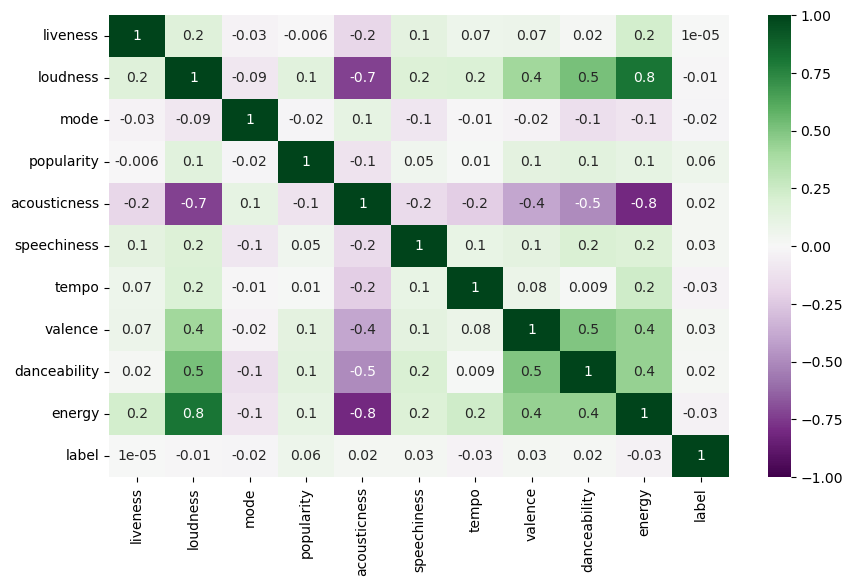

In [42]:
df_num = df.select_dtypes(exclude=['O'])
plt.figure(figsize=(10,6))
sns.heatmap(df_num.corr(),annot=True,fmt='.0g',cmap='PRGn',vmin=-1, vmax=1)

In [51]:
# Separate the data again for location exploratory data analysis
# List of categories you want to filter (starting with these values)
categories = ['gym', 'bedroom', 'trainbus', 'library', 'restaurant', 'office', 'bar', 'mall']

# Loop through the categories, filter the rows that start with the category, and store each DataFrame
for category in categories:
    filtered_df = df[df['target_group'].str.startswith(category)]
    globals()[f'{category}_df'] = filtered_df

# Display the filtered DataFrames
for category in categories:
    print(f"\nData for {category}:")
    print(globals()[f'{category}_df'])



Data for gym:
      liveness  mode  popularity  acousticness  speechiness    tempo  valence  \
0       0.3750     1          84       0.00598       0.0488  172.090    0.244   
1       0.0937     1          83       0.00260       0.0568  104.983    0.606   
2       0.1210     0          52       0.38500       0.0527   90.030    0.525   
3       0.1490     1          82       0.08470       0.0484  130.049    0.430   
4       0.2850     0          82       0.11900       0.0903  130.001    0.220   
...        ...   ...         ...           ...          ...      ...      ...   
3541    0.1620     1          59       0.00015       0.0344  155.011    0.286   
3542    0.1720     0          61       0.00984       0.0391  133.922    0.397   
3543    0.1510     0          58       0.03210       0.0449  129.852    0.372   
3544    0.2800     0          58       0.04410       0.0914  130.077    0.478   
3545    0.1840     0          58       0.01330       0.0563  133.011    0.203   

      dancea

# Numerical Features Distribution and Pair-Wise Relationship Across Song Preference Label 

## Gym

/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), whic

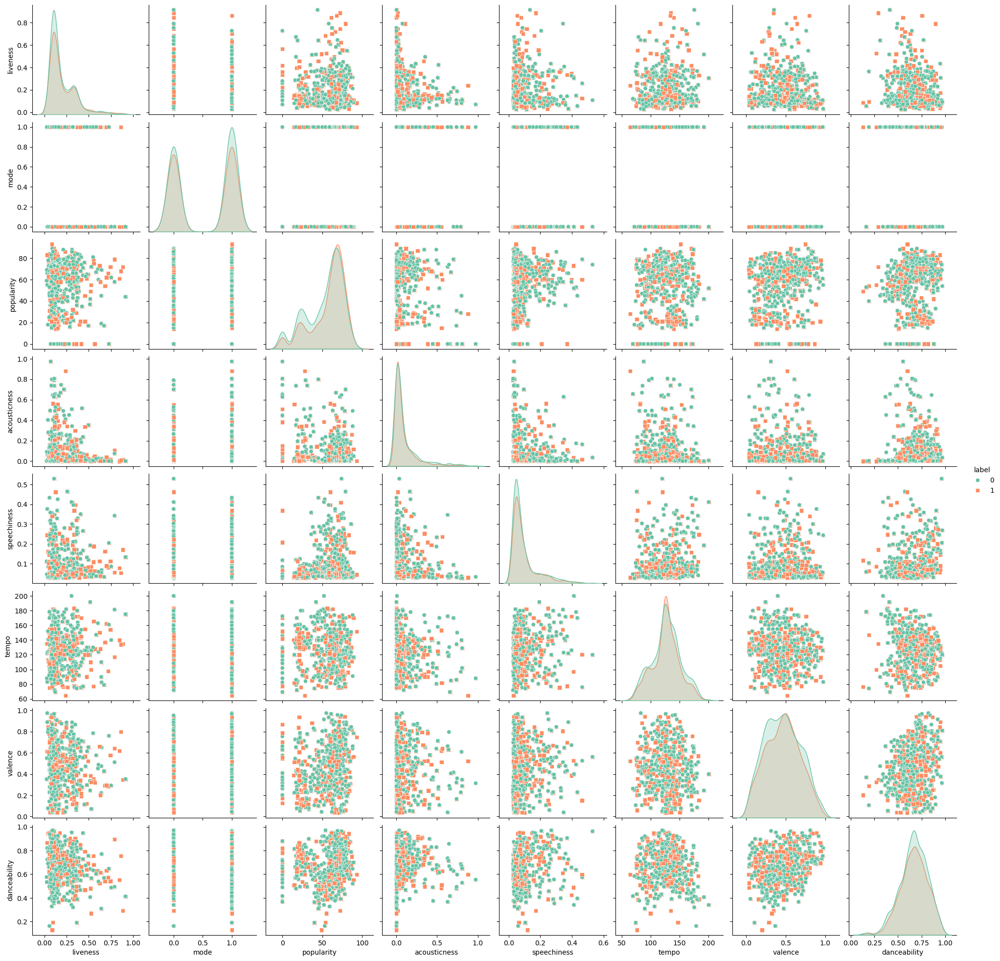

In [53]:
sns.pairplot(gym_df, hue='label', palette='Set2', diag_kind='kde', markers=['o', 's', 'D'])
plt.show()

## Bedroom

/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), whic

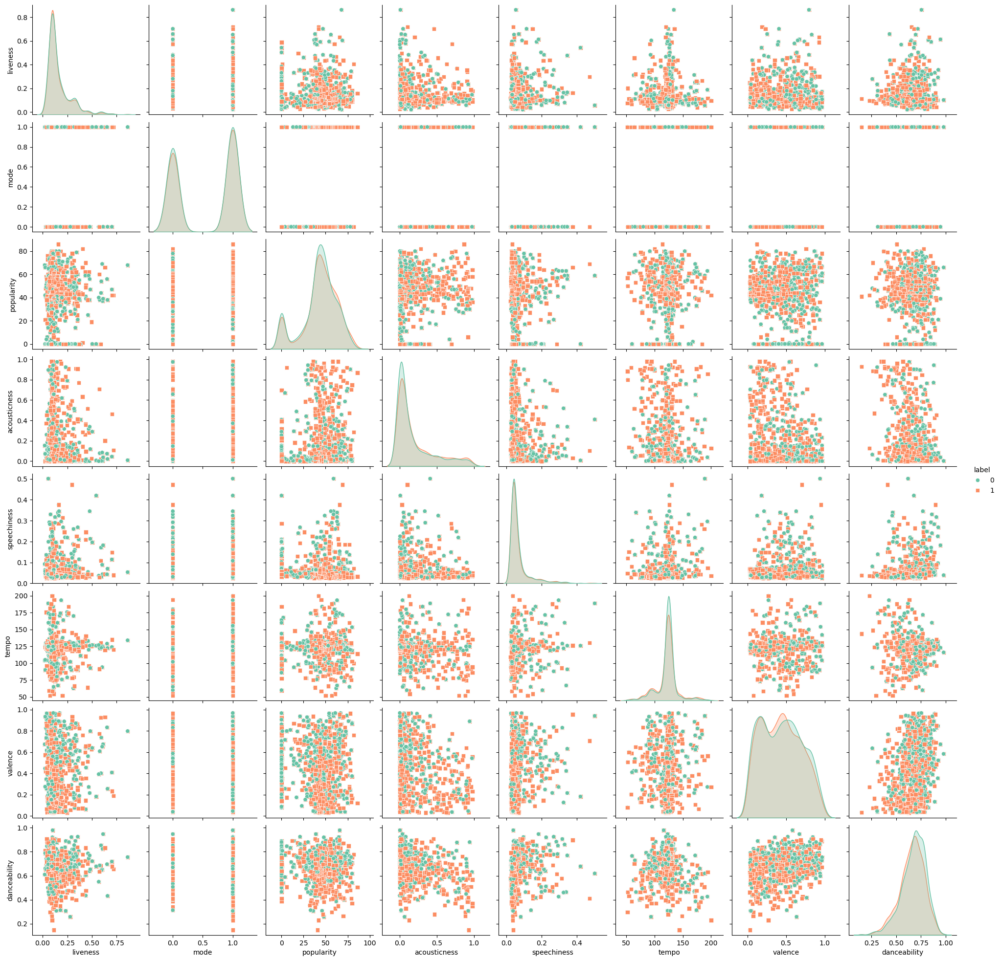

In [54]:
sns.pairplot(bedroom_df, hue='label', palette='Set2', diag_kind='kde', markers=['o', 's', 'D'])
plt.show()

## TrainBus

/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), whic

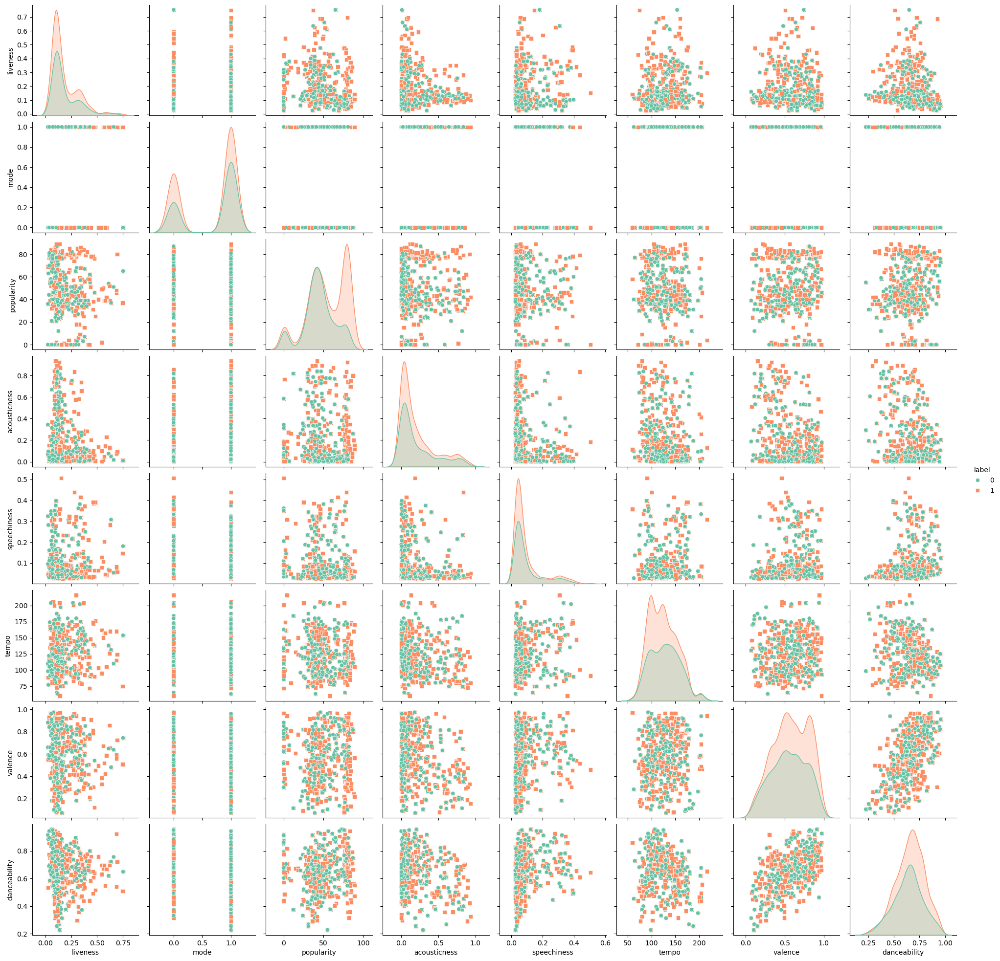

In [55]:
sns.pairplot(trainbus_df, hue='label', palette='Set2', diag_kind='kde', markers=['o', 's', 'D'])
plt.show()

## Library

/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), whic

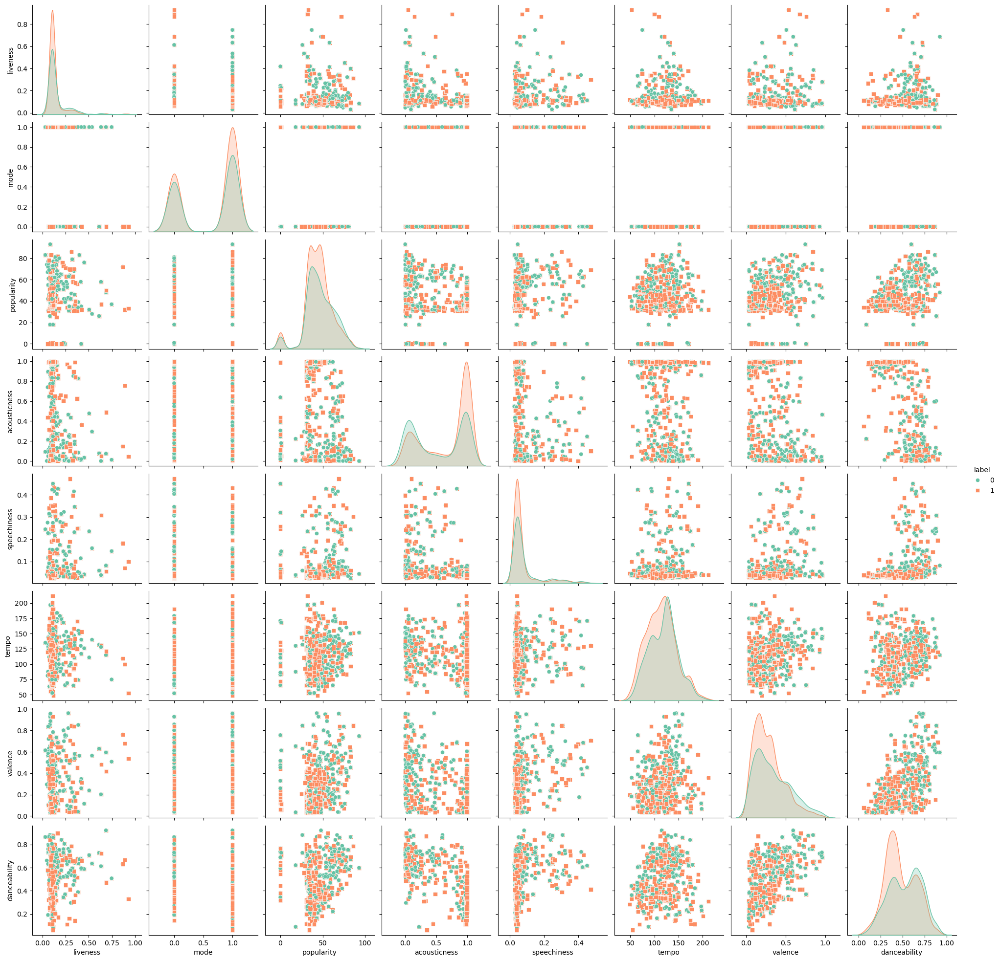

In [56]:
sns.pairplot(library_df, hue='label', palette='Set2', diag_kind='kde', markers=['o', 's', 'D'])
plt.show()

## Restaurant

/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), whic

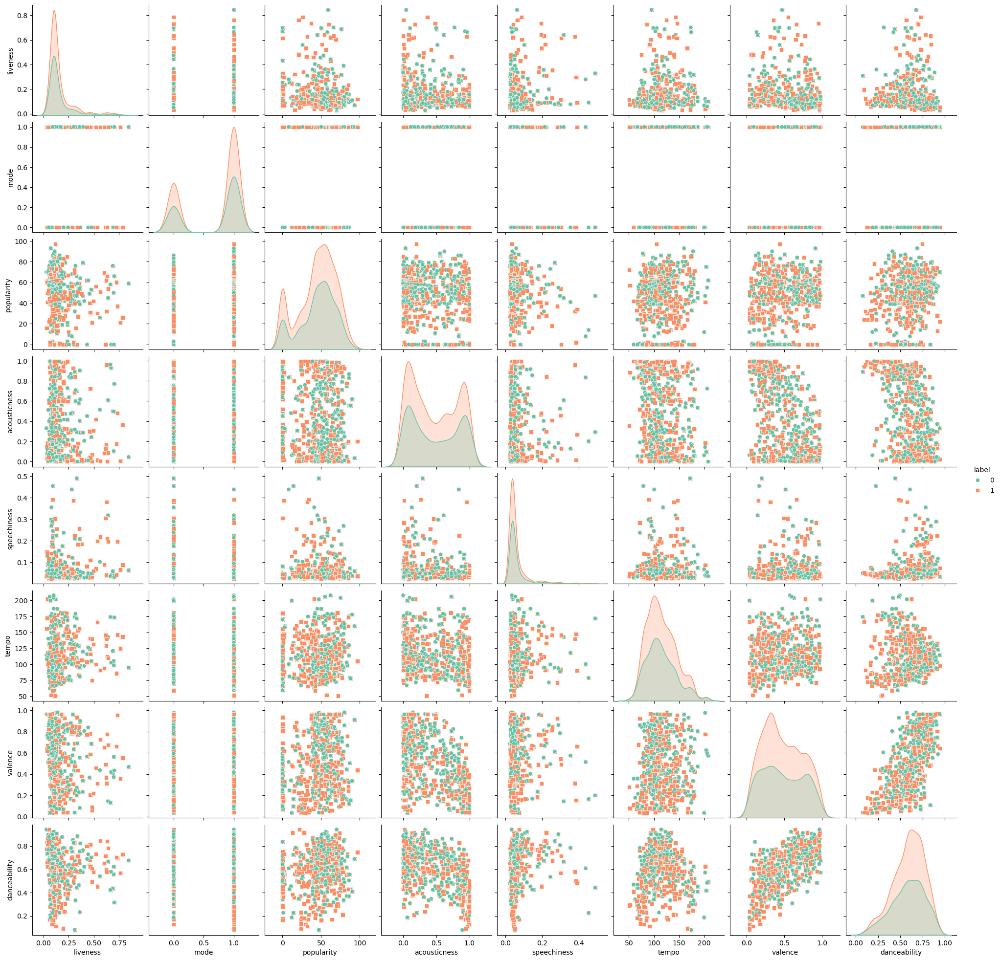

In [57]:
sns.pairplot(restaurant_df, hue='label', palette='Set2', diag_kind='kde', markers=['o', 's', 'D'])
plt.show()

## Office

/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), whic

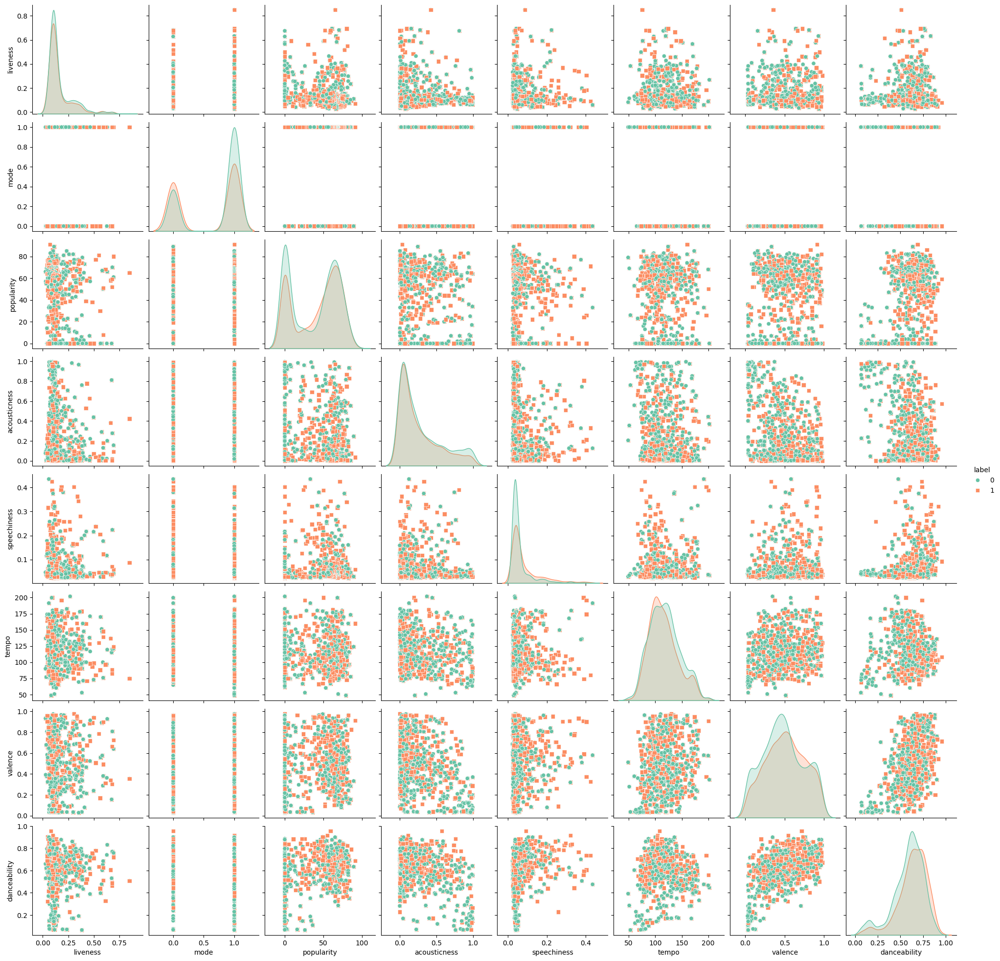

In [58]:
sns.pairplot(office_df, hue='label', palette='Set2', diag_kind='kde', markers=['o', 's', 'D'])
plt.show()

## Bar

/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), whic

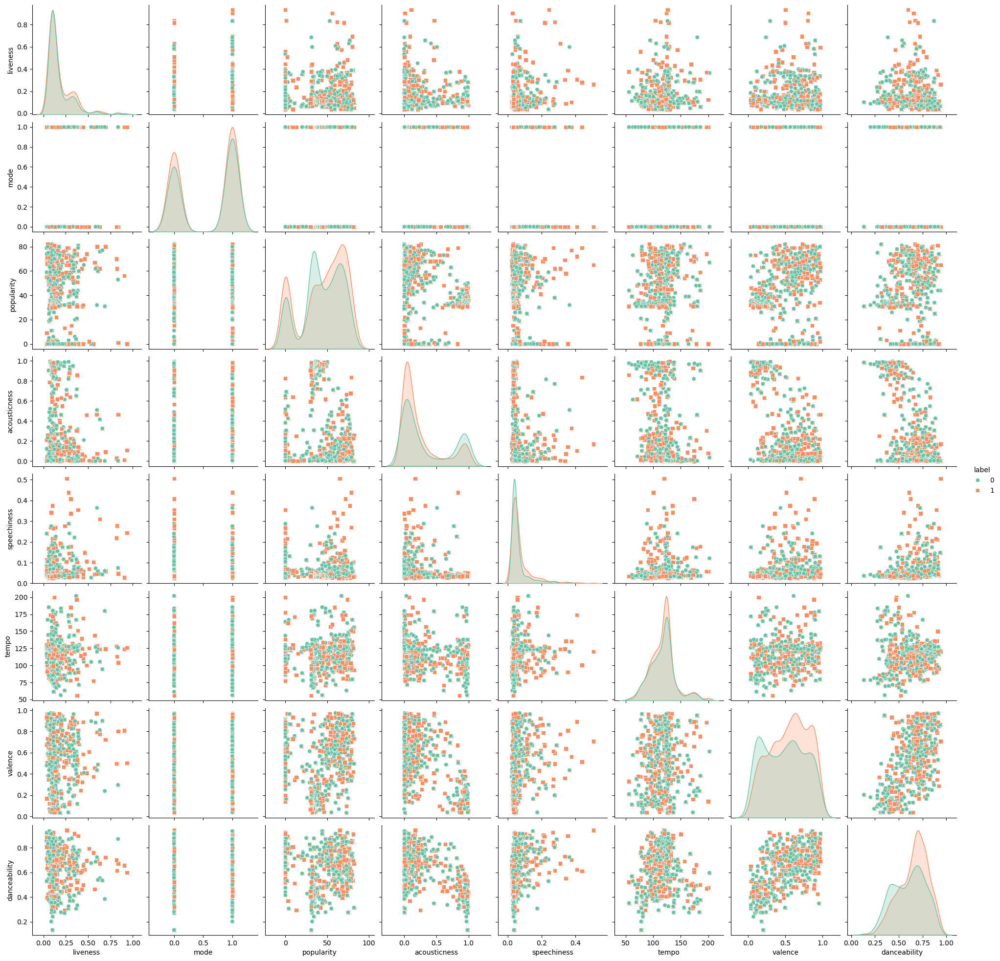

In [59]:
sns.pairplot(bar_df, hue='label', palette='Set2', diag_kind='kde', markers=['o', 's', 'D'])
plt.show()

## Mall

/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), which may not be intended.
  func(x=x, y=y, **kwargs)
/opt/homebrew/anaconda3/envs/Lab3/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: The markers list has more values (3) than needed (2), whic

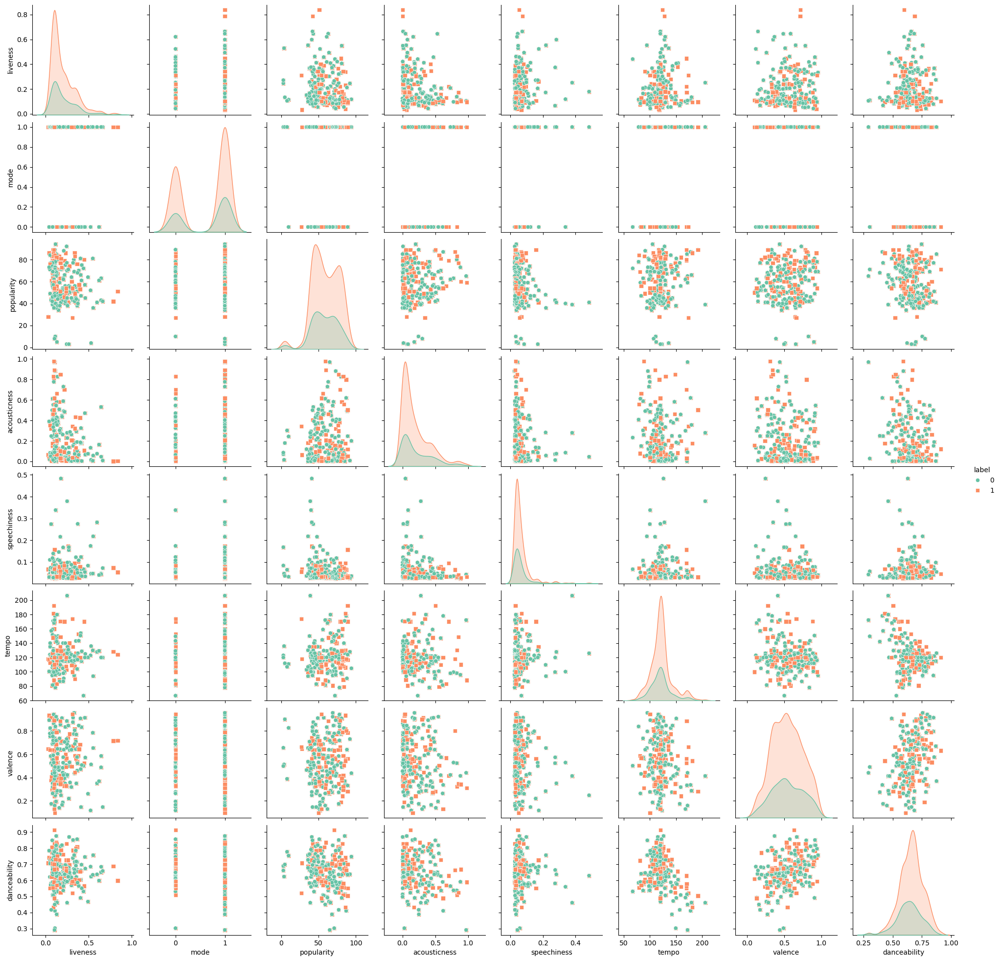

In [60]:
sns.pairplot(mall_df, hue='label', palette='Set2', diag_kind='kde', markers=['o', 's', 'D'])
plt.show()

# Exploratory Analysis of Song Preference Label Across Categorical Values

In [112]:
import matplotlib.pyplot as plt
import pandas as pd

# Function to plot proportions for a given DataFrame and column
def plot_proportional_comparison(df, column_name, title, xlabel):
    # Calculate the count for each category per label
    count_df = df.groupby([column_name, 'label']).size().reset_index(name='count')

    # Calculate the total count per mood/category
    total_count_df = df[column_name].value_counts().reset_index()
    total_count_df.columns = [column_name, 'total_count']

    # Merge the counts with the total counts to calculate proportions
    proportion_df = pd.merge(count_df, total_count_df, on=column_name)
    proportion_df['proportion'] = proportion_df['count'] / proportion_df['total_count']

    # Pivot the data to prepare for plotting
    proportion_pivot = proportion_df.pivot(index=column_name, columns='label', values='proportion').fillna(0)
    proportion_pivot.columns = ['label_0', 'label_1']
    proportion_pivot.reset_index(inplace=True)

    # Plot a grouped bar chart for proportions
    proportion_pivot.plot(
        x=column_name, 
        kind='bar', 
        stacked=False, 
        figsize=(12, 8),
        color=['#1f77b4', '#ff7f0e'],
        width=0.8
    )

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel('Proportion')
    plt.xticks(rotation=45)
    plt.legend(['Label 0', 'Label 1'])
    plt.tight_layout()
    plt.show()

## Gym

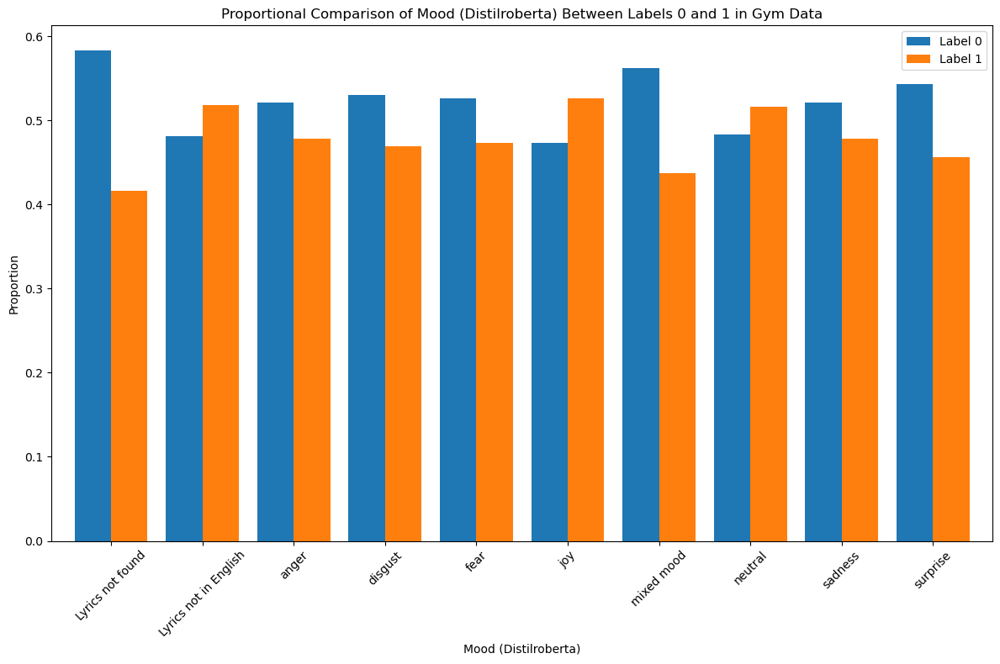

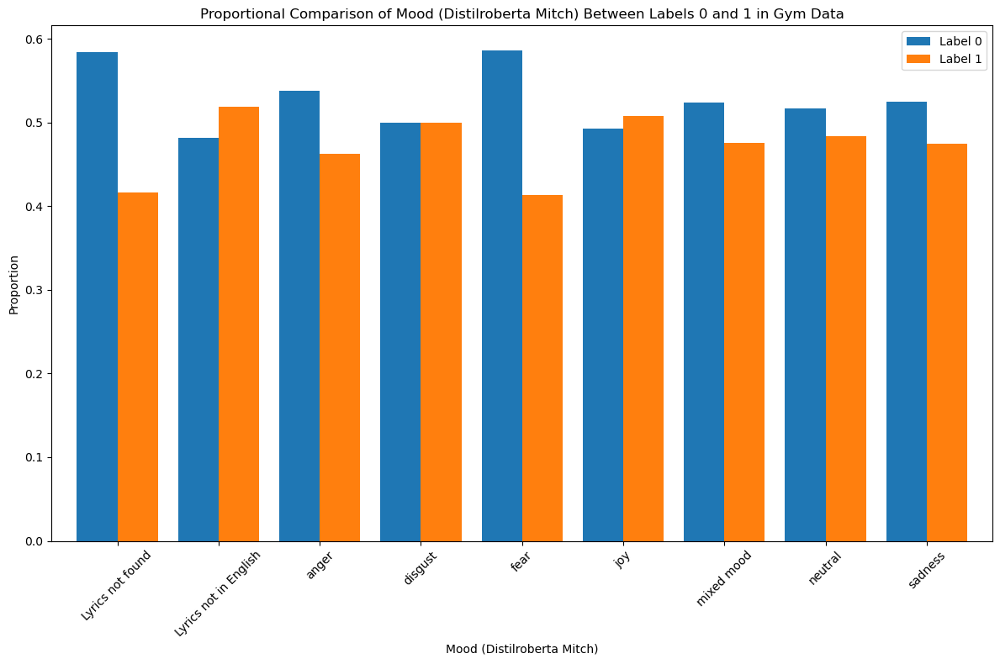

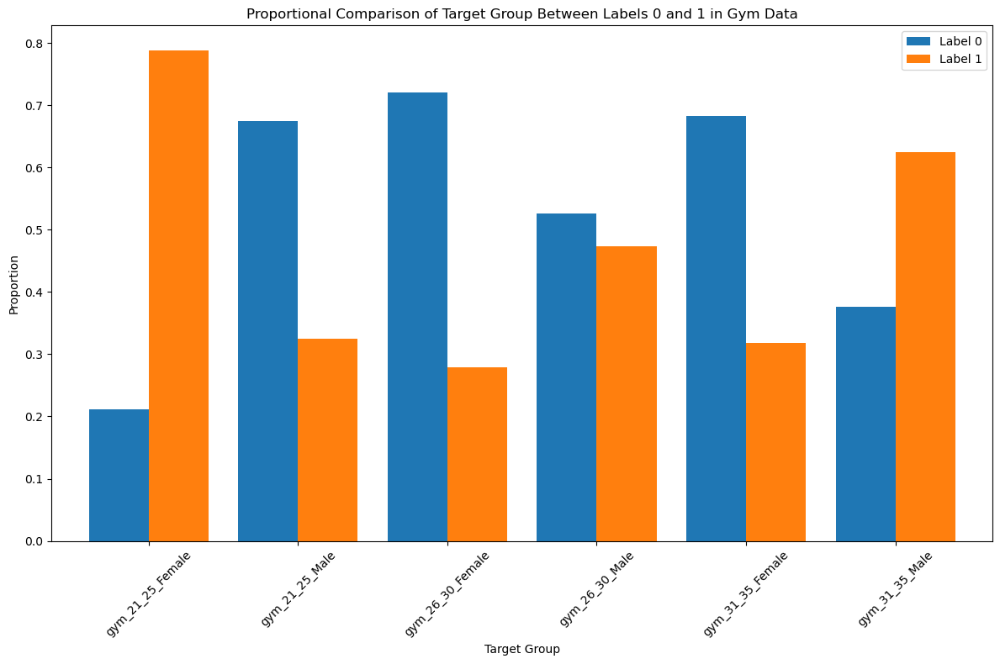

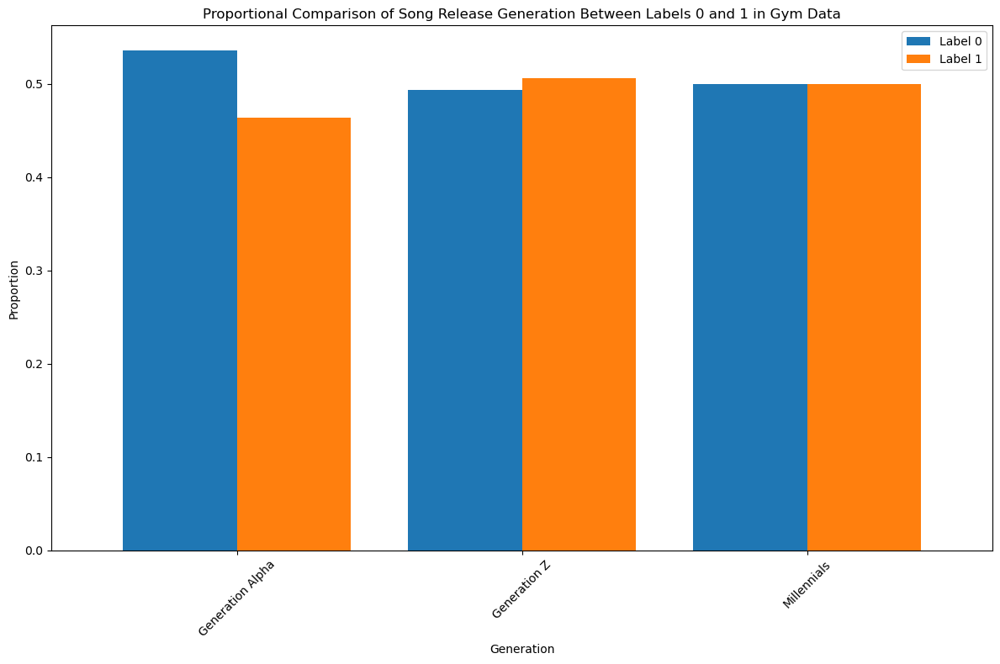

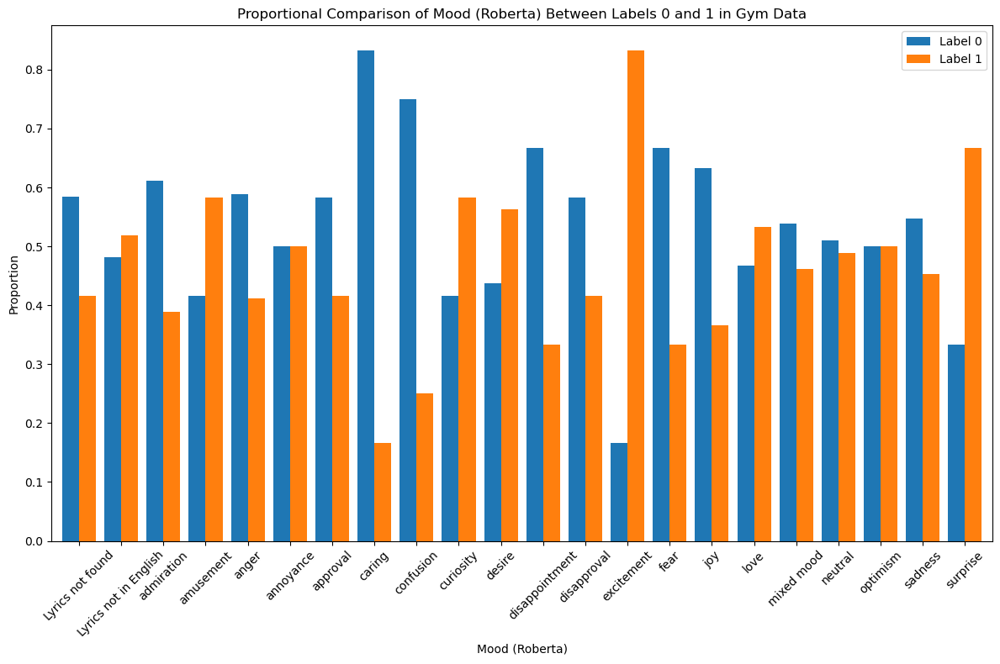

In [114]:

plot_proportional_comparison(
    df=gym_df, 
    column_name='final_mood_jhart', 
    title='Proportional Comparison of Mood (Distilroberta) Between Labels 0 and 1 in Gym Data', 
    xlabel='Mood (Distilroberta)'
)


plot_proportional_comparison(
    df=gym_df, 
    column_name='final_mood_mitch', 
    title='Proportional Comparison of Mood (Distilroberta Mitch) Between Labels 0 and 1 in Gym Data', 
    xlabel='Mood (Distilroberta Mitch)'
)


plot_proportional_comparison(
    df=gym_df, 
    column_name='target_group', 
    title='Proportional Comparison of Target Group Between Labels 0 and 1 in Gym Data', 
    xlabel='Target Group'
)


plot_proportional_comparison(
    df=gym_df, 
    column_name='generation', 
    title='Proportional Comparison of Song Release Generation Between Labels 0 and 1 in Gym Data', 
    xlabel='Generation'
)


plot_proportional_comparison(
    df=gym_df, 
    column_name='final_mood_roberta', 
    title='Proportional Comparison of Mood (Roberta) Between Labels 0 and 1 in Gym Data', 
    xlabel='Mood (Roberta)'
)


## Library

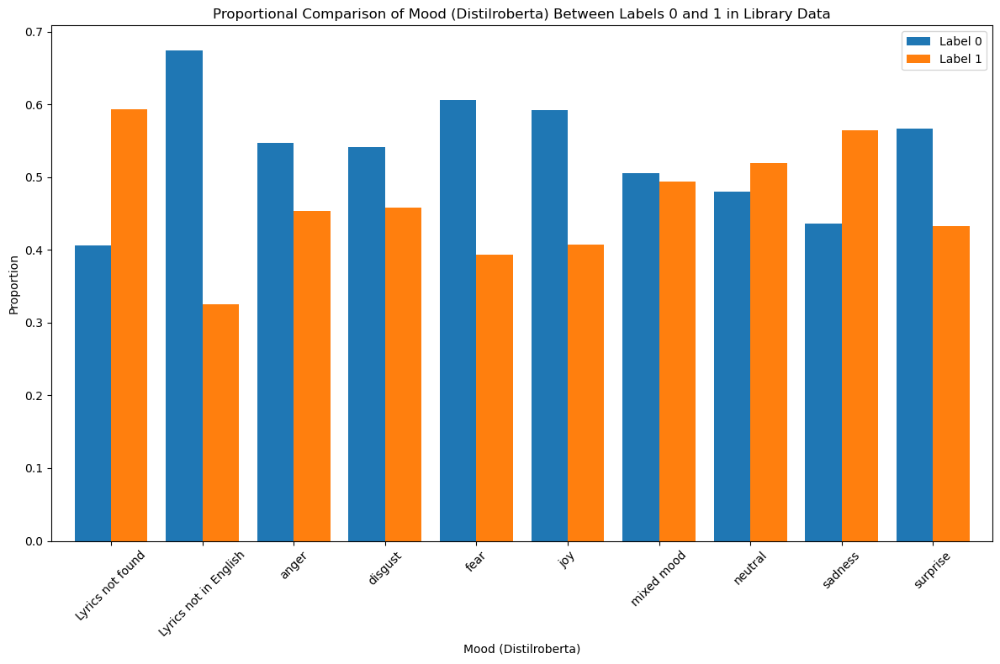

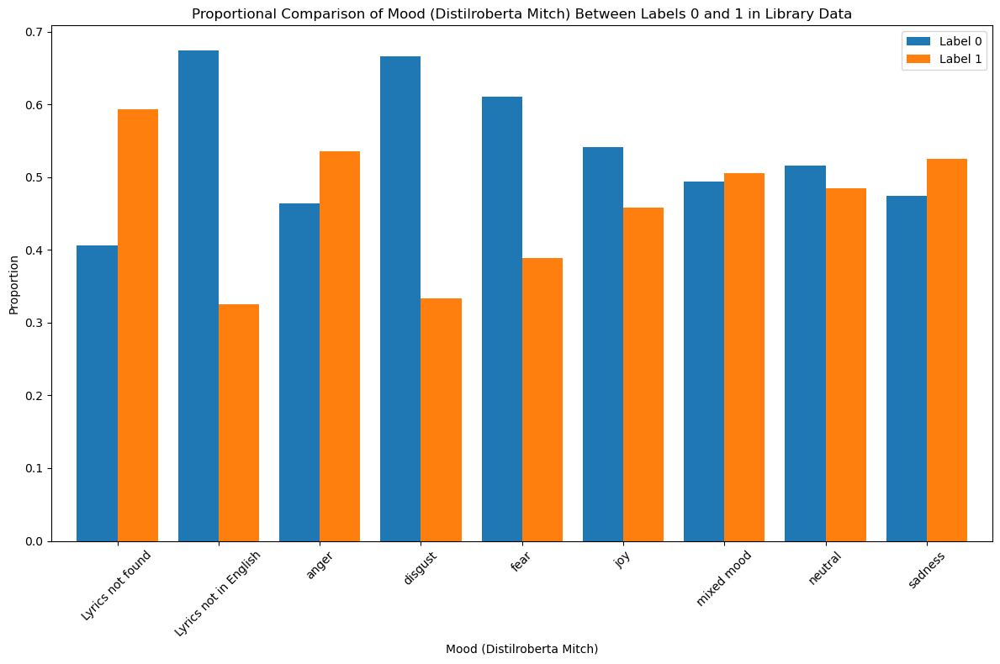

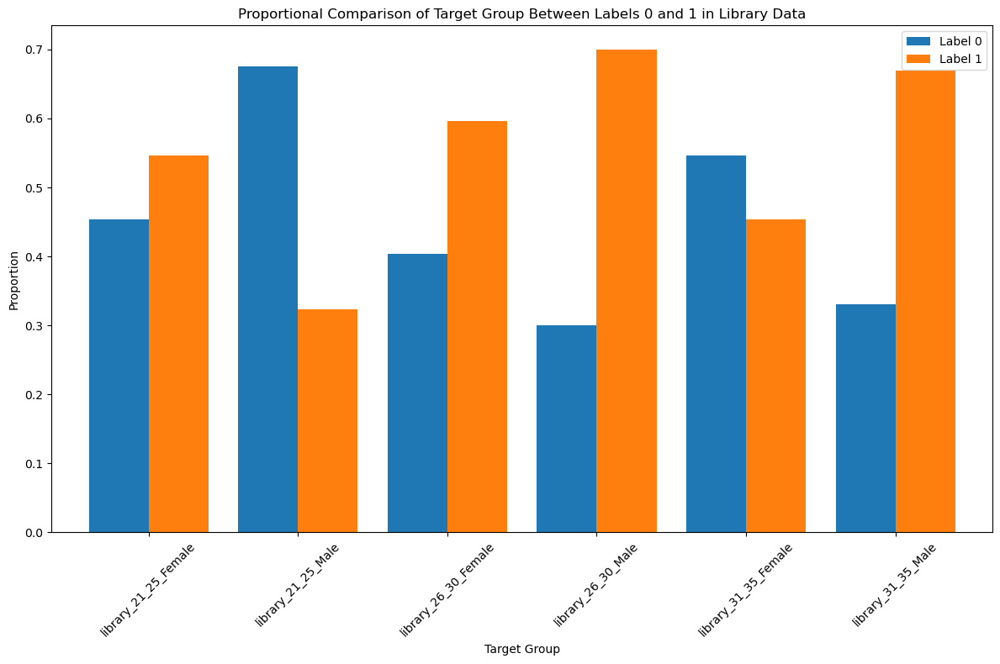

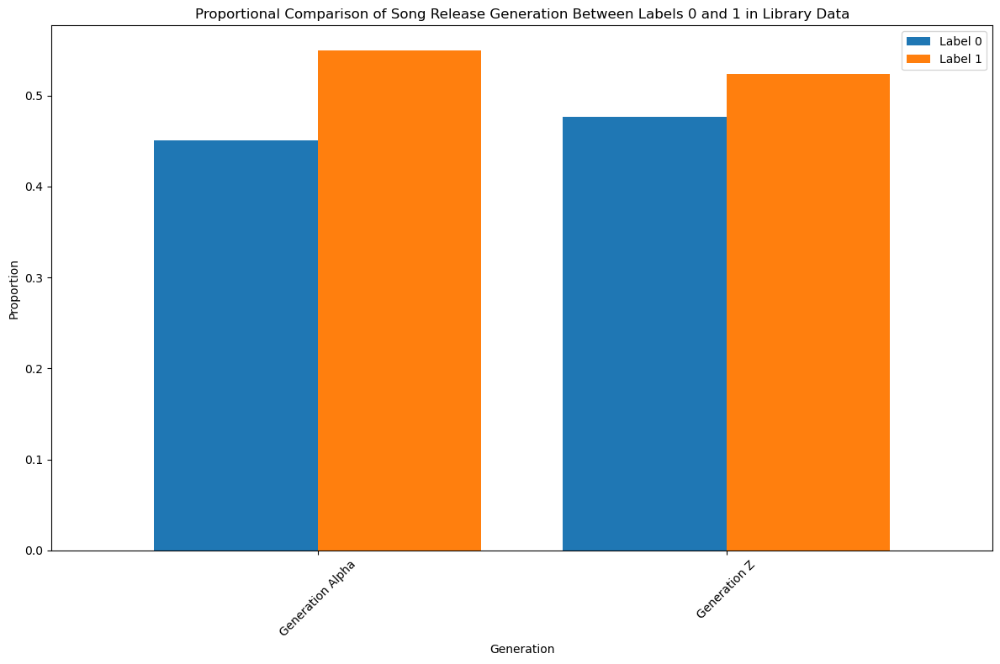

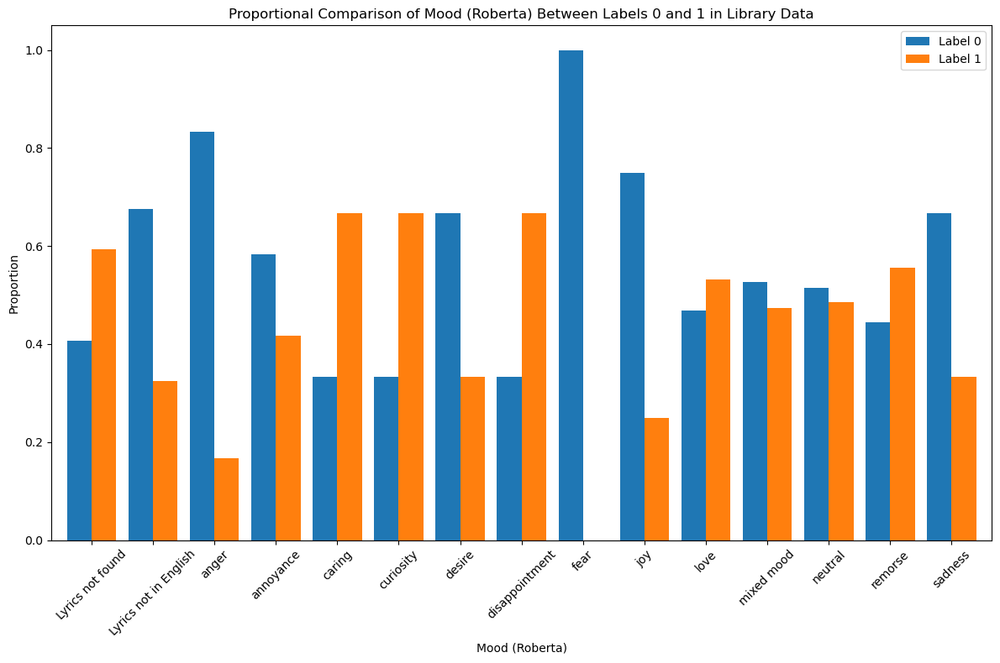

In [115]:

plot_proportional_comparison(
    df=library_df, 
    column_name='final_mood_jhart', 
    title='Proportional Comparison of Mood (Distilroberta) Between Labels 0 and 1 in Library Data', 
    xlabel='Mood (Distilroberta)'
)


plot_proportional_comparison(
    df=library_df, 
    column_name='final_mood_mitch', 
    title='Proportional Comparison of Mood (Distilroberta Mitch) Between Labels 0 and 1 in Library Data', 
    xlabel='Mood (Distilroberta Mitch)'
)


plot_proportional_comparison(
    df=library_df, 
    column_name='target_group', 
    title='Proportional Comparison of Target Group Between Labels 0 and 1 in Library Data', 
    xlabel='Target Group'
)


plot_proportional_comparison(
    df=library_df, 
    column_name='generation', 
    title='Proportional Comparison of Song Release Generation Between Labels 0 and 1 in Library Data', 
    xlabel='Generation'
)


plot_proportional_comparison(
    df=library_df, 
    column_name='final_mood_roberta', 
    title='Proportional Comparison of Mood (Roberta) Between Labels 0 and 1 in Library Data', 
    xlabel='Mood (Roberta)'
)


## Mall

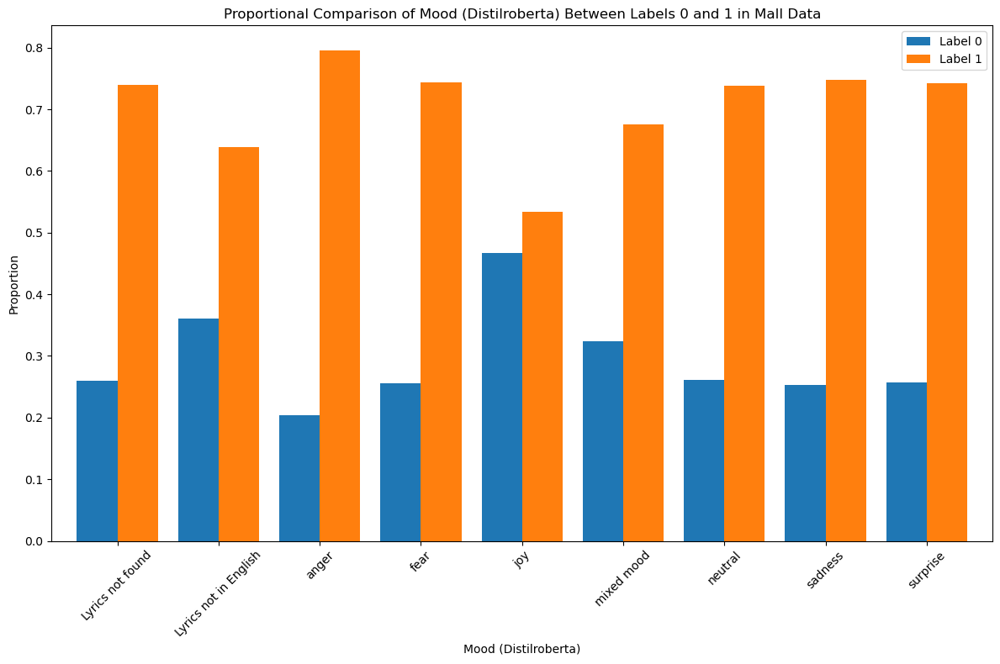

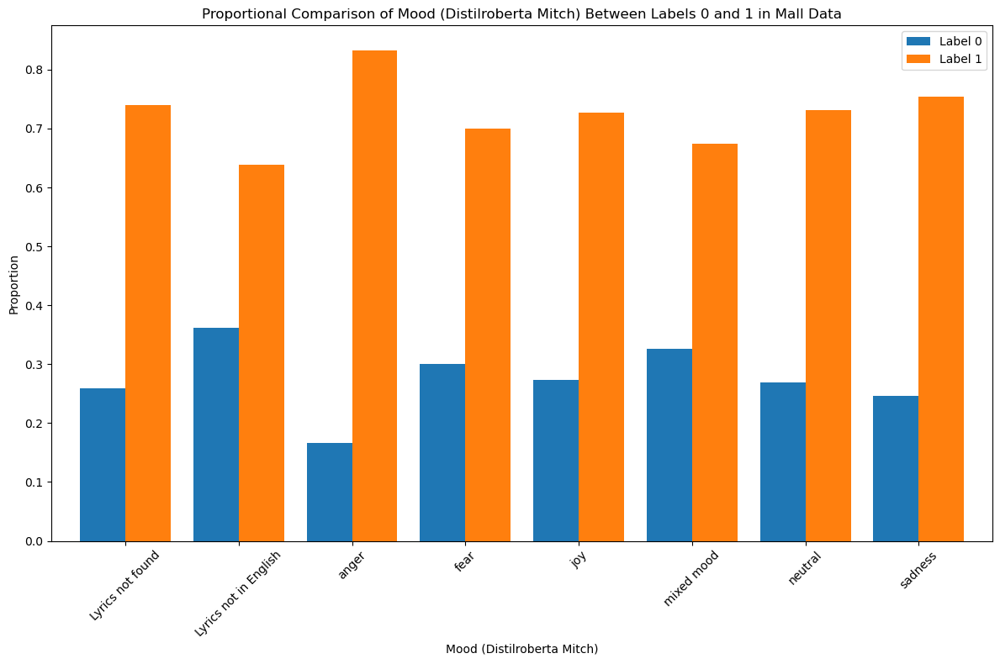

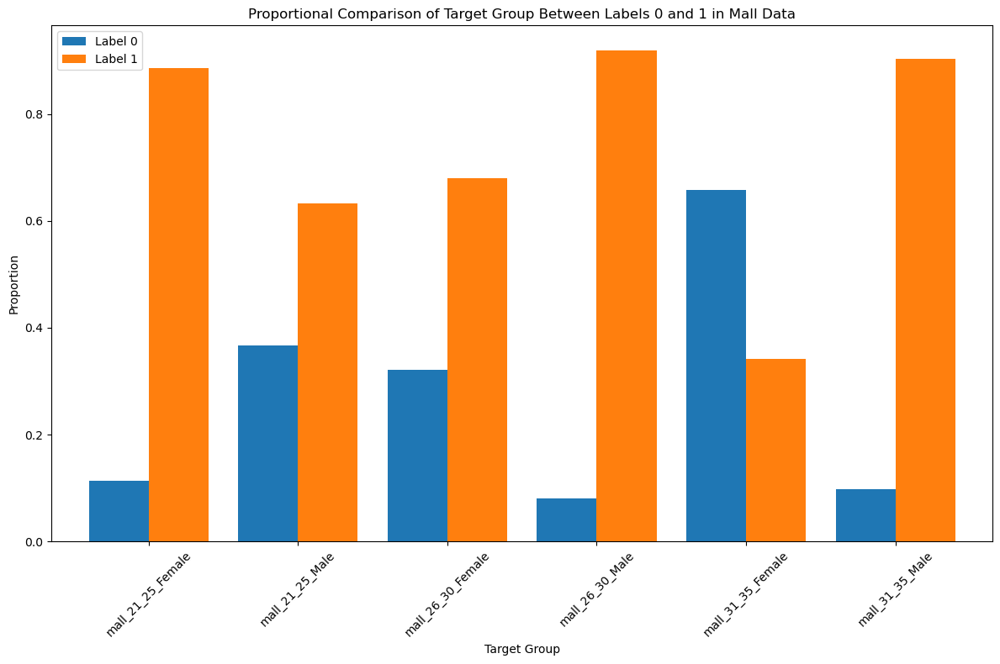

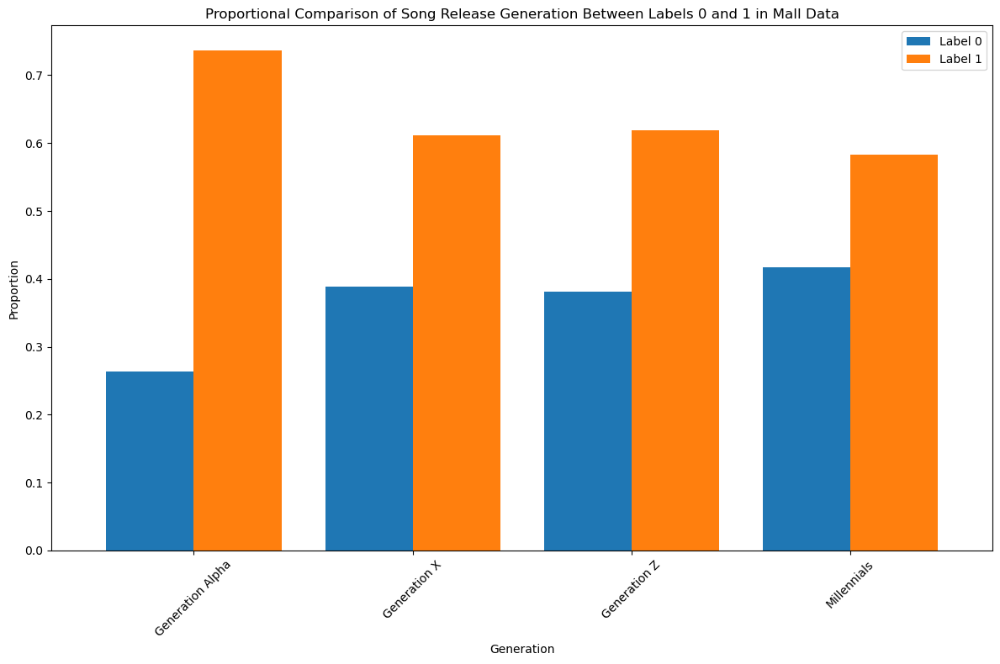

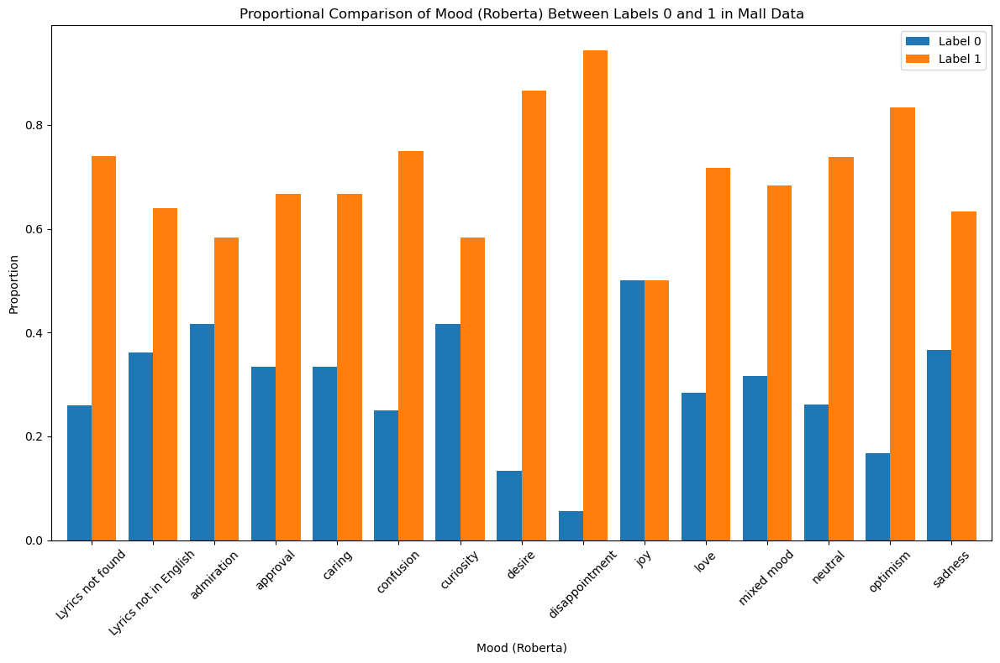

In [116]:

plot_proportional_comparison(
    df=mall_df, 
    column_name='final_mood_jhart', 
    title='Proportional Comparison of Mood (Distilroberta) Between Labels 0 and 1 in Mall Data', 
    xlabel='Mood (Distilroberta)'
)


plot_proportional_comparison(
    df=mall_df, 
    column_name='final_mood_mitch', 
    title='Proportional Comparison of Mood (Distilroberta Mitch) Between Labels 0 and 1 in Mall Data', 
    xlabel='Mood (Distilroberta Mitch)'
)


plot_proportional_comparison(
    df=mall_df, 
    column_name='target_group', 
    title='Proportional Comparison of Target Group Between Labels 0 and 1 in Mall Data', 
    xlabel='Target Group'
)


plot_proportional_comparison(
    df=mall_df, 
    column_name='generation', 
    title='Proportional Comparison of Song Release Generation Between Labels 0 and 1 in Mall Data', 
    xlabel='Generation'
)


plot_proportional_comparison(
    df=mall_df, 
    column_name='final_mood_roberta', 
    title='Proportional Comparison of Mood (Roberta) Between Labels 0 and 1 in Mall Data', 
    xlabel='Mood (Roberta)'
)


## TrainBus

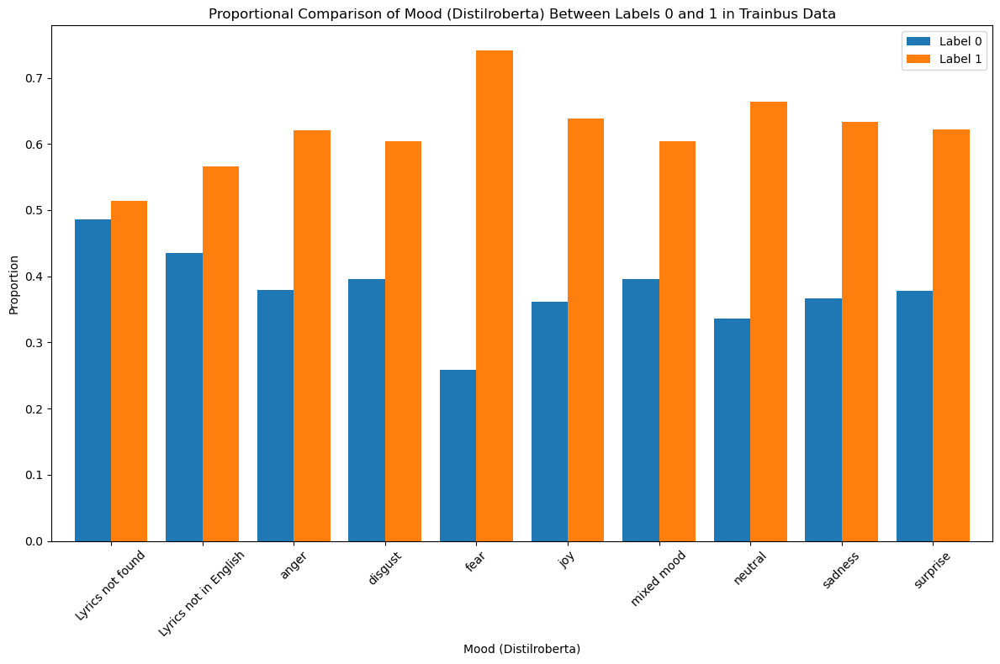

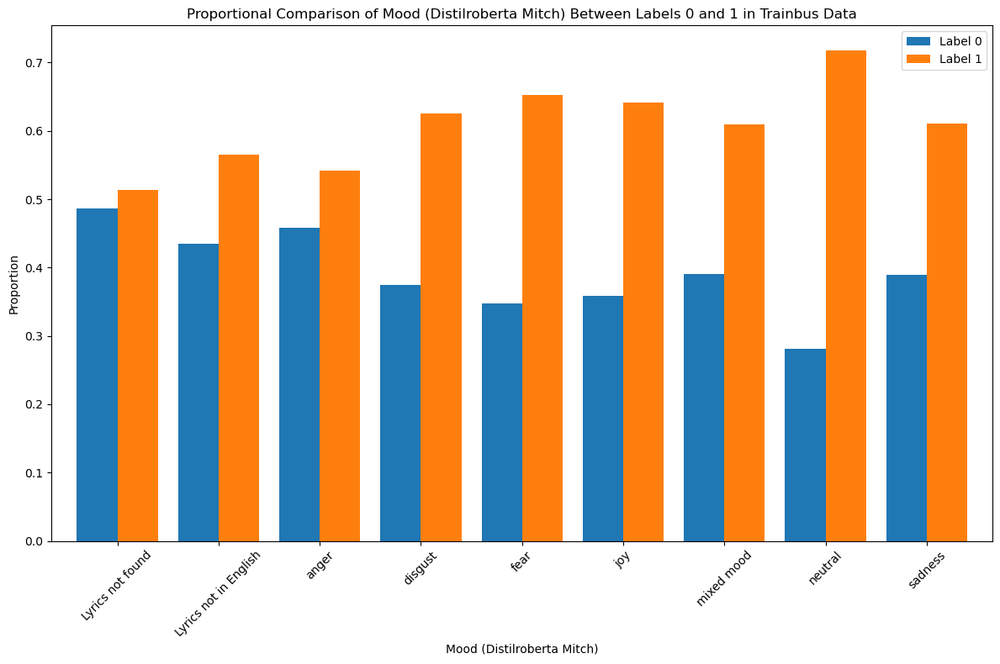

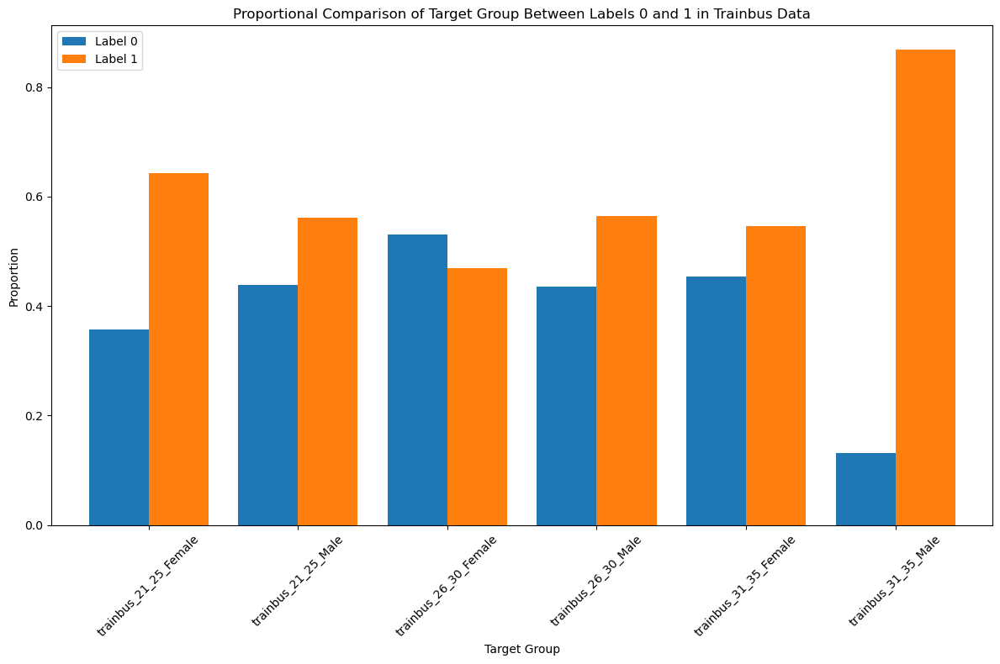

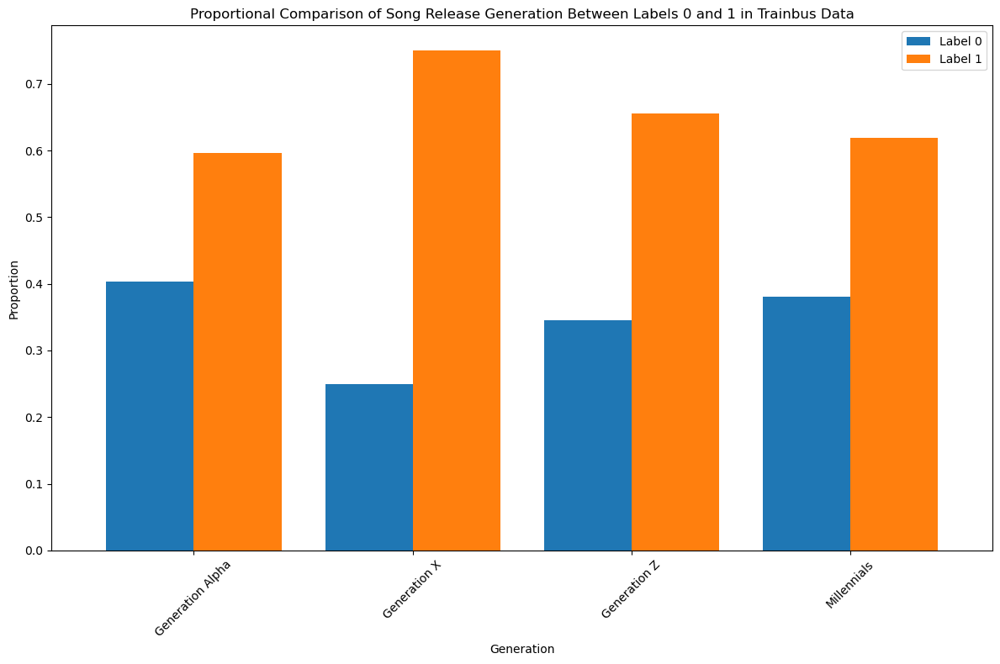

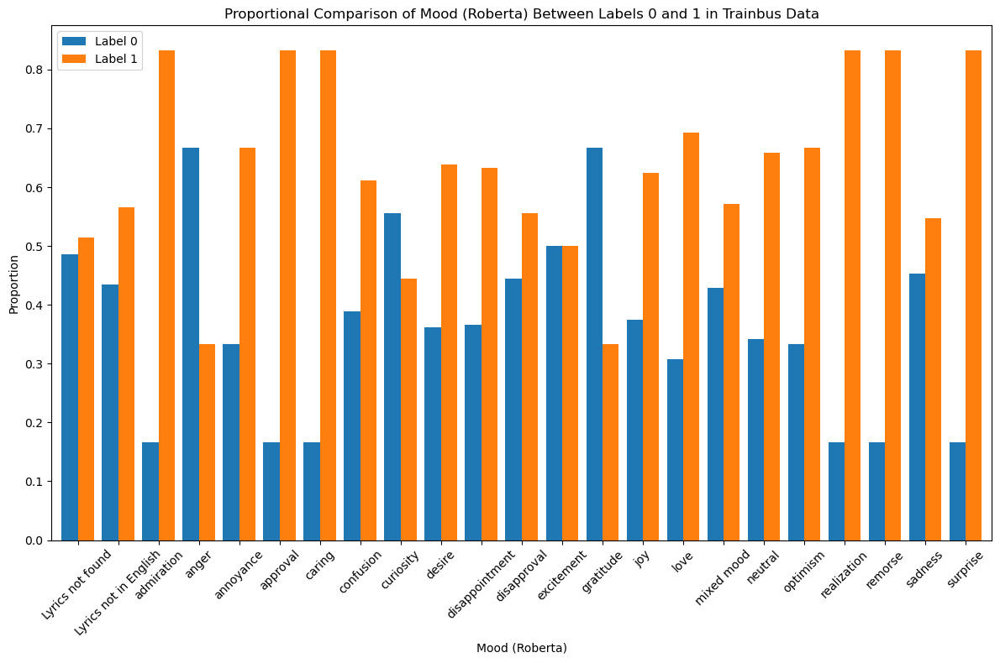

In [117]:

plot_proportional_comparison(
    df=trainbus_df, 
    column_name='final_mood_jhart', 
    title='Proportional Comparison of Mood (Distilroberta) Between Labels 0 and 1 in Trainbus Data', 
    xlabel='Mood (Distilroberta)'
)


plot_proportional_comparison(
    df=trainbus_df, 
    column_name='final_mood_mitch', 
    title='Proportional Comparison of Mood (Distilroberta Mitch) Between Labels 0 and 1 in Trainbus Data', 
    xlabel='Mood (Distilroberta Mitch)'
)


plot_proportional_comparison(
    df=trainbus_df, 
    column_name='target_group', 
    title='Proportional Comparison of Target Group Between Labels 0 and 1 in Trainbus Data', 
    xlabel='Target Group'
)


plot_proportional_comparison(
    df=trainbus_df, 
    column_name='generation', 
    title='Proportional Comparison of Song Release Generation Between Labels 0 and 1 in Trainbus Data', 
    xlabel='Generation'
)


plot_proportional_comparison(
    df=trainbus_df, 
    column_name='final_mood_roberta', 
    title='Proportional Comparison of Mood (Roberta) Between Labels 0 and 1 in Trainbus Data', 
    xlabel='Mood (Roberta)'
)


## Restaurant 

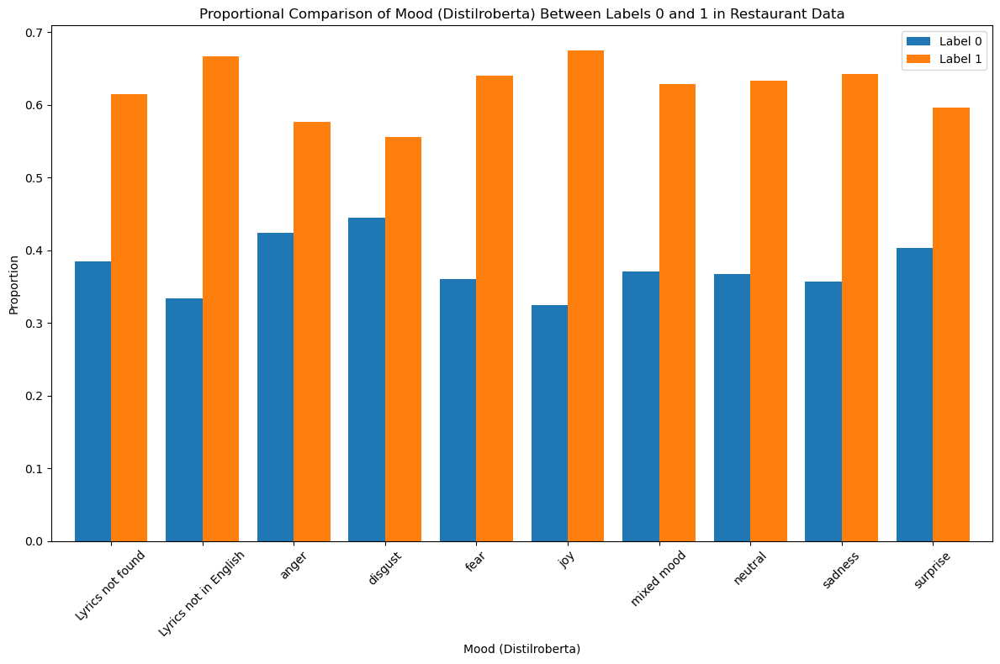

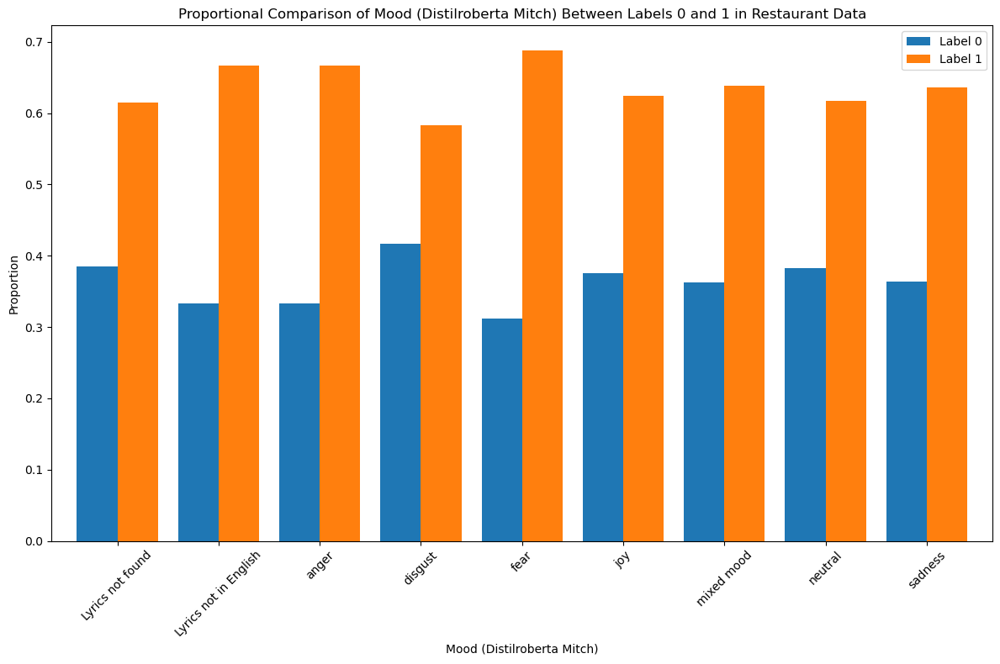

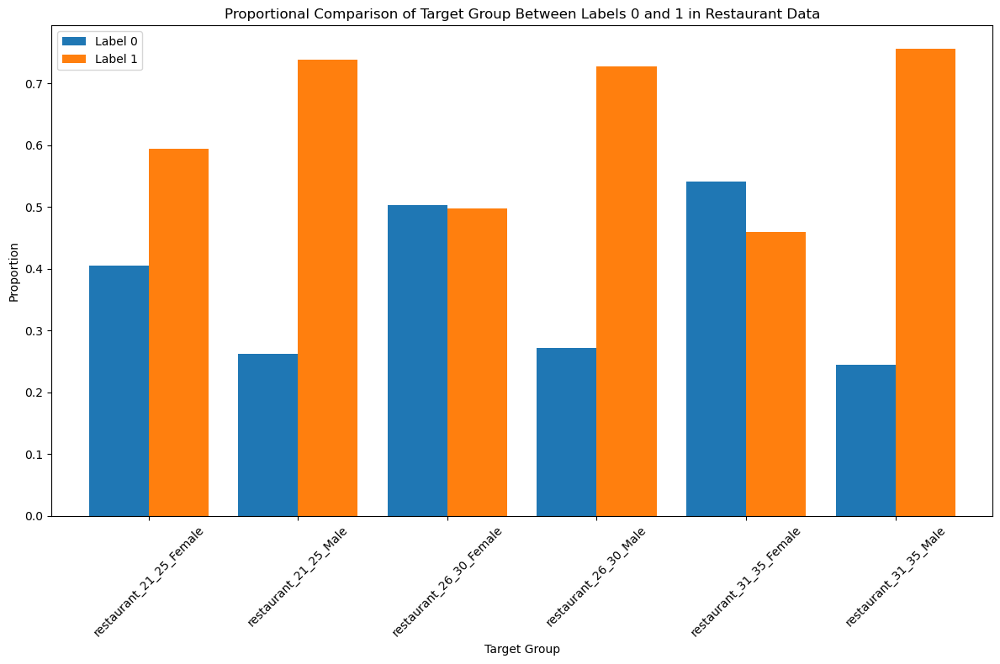

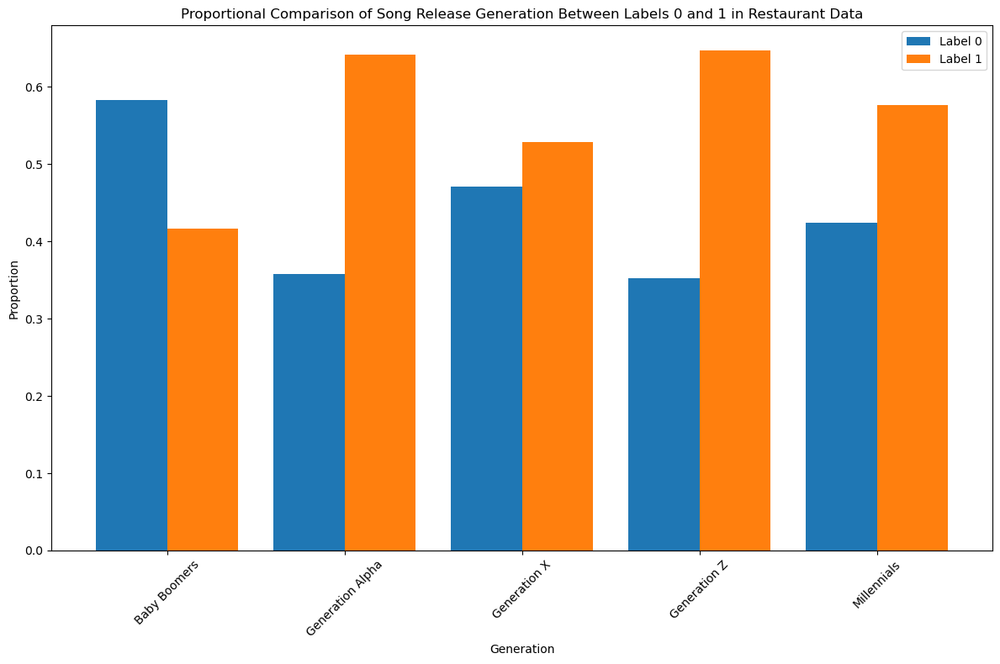

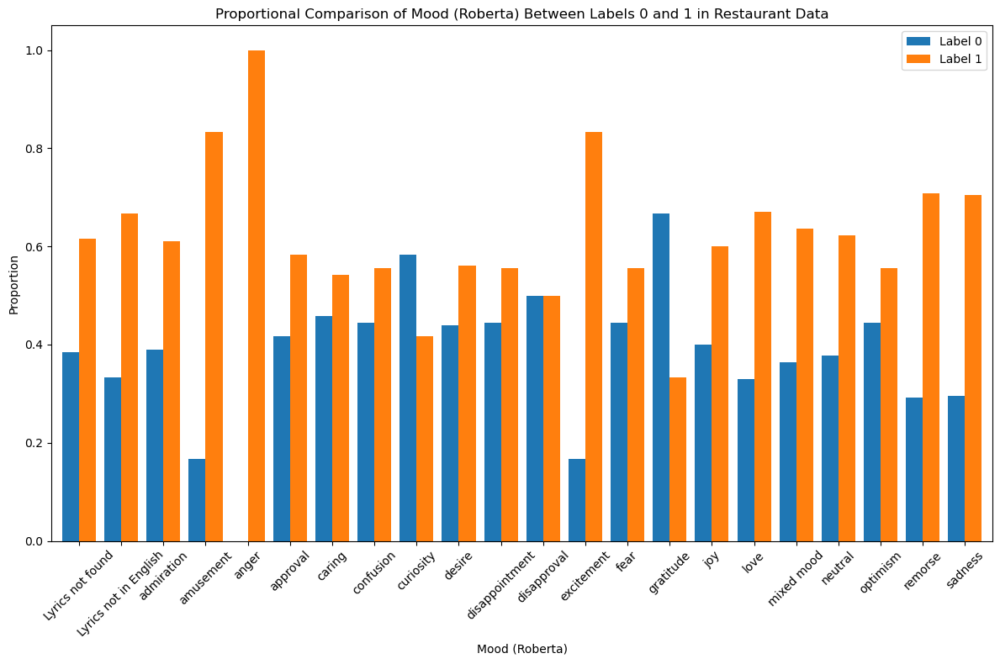

In [118]:

plot_proportional_comparison(
    df=restaurant_df, 
    column_name='final_mood_jhart', 
    title='Proportional Comparison of Mood (Distilroberta) Between Labels 0 and 1 in Restaurant Data', 
    xlabel='Mood (Distilroberta)'
)


plot_proportional_comparison(
    df=restaurant_df, 
    column_name='final_mood_mitch', 
    title='Proportional Comparison of Mood (Distilroberta Mitch) Between Labels 0 and 1 in Restaurant Data', 
    xlabel='Mood (Distilroberta Mitch)'
)


plot_proportional_comparison(
    df=restaurant_df, 
    column_name='target_group', 
    title='Proportional Comparison of Target Group Between Labels 0 and 1 in Restaurant Data', 
    xlabel='Target Group'
)


plot_proportional_comparison(
    df=restaurant_df, 
    column_name='generation', 
    title='Proportional Comparison of Song Release Generation Between Labels 0 and 1 in Restaurant Data', 
    xlabel='Generation'
)


plot_proportional_comparison(
    df=restaurant_df, 
    column_name='final_mood_roberta', 
    title='Proportional Comparison of Mood (Roberta) Between Labels 0 and 1 in Restaurant Data', 
    xlabel='Mood (Roberta)'
)


## Office

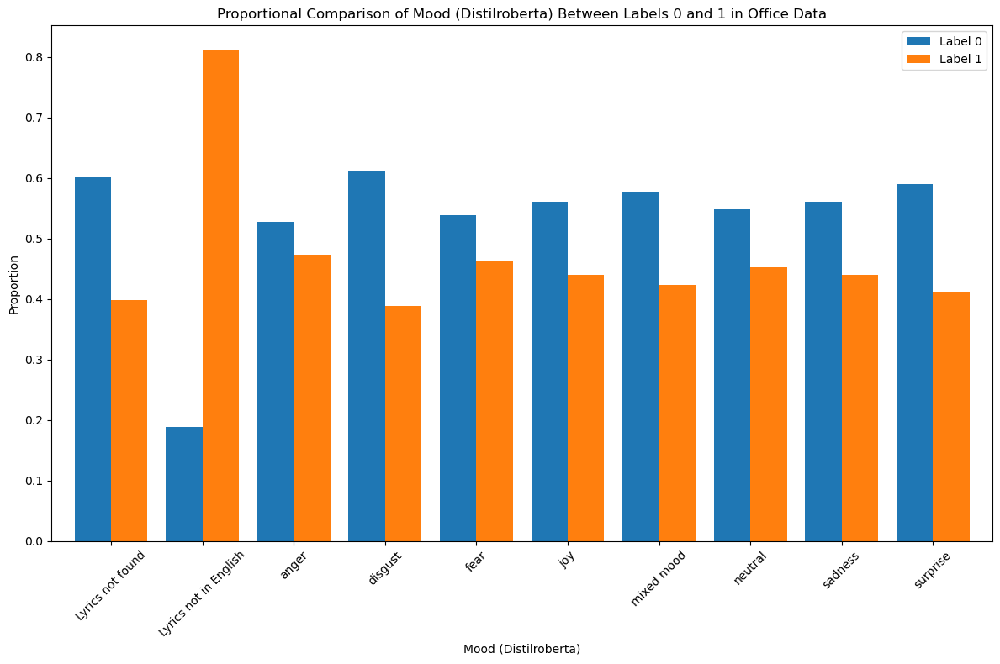

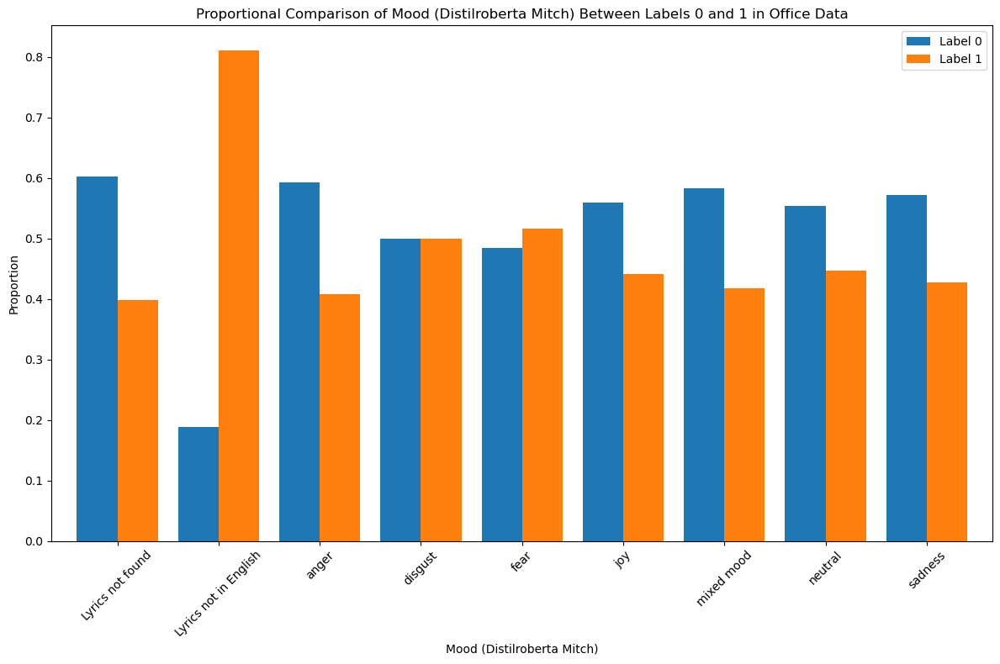

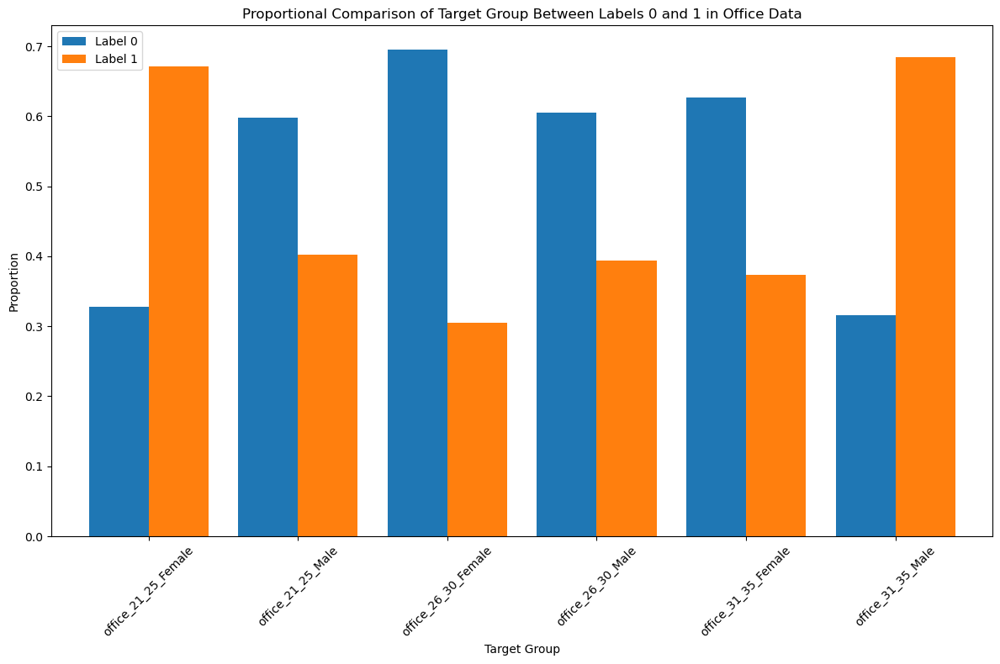

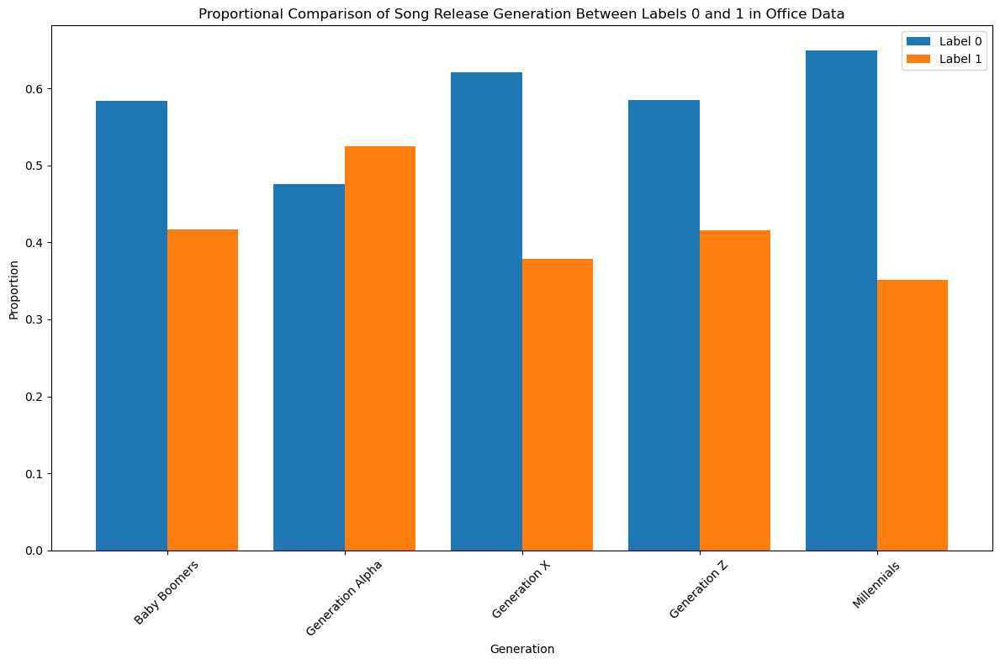

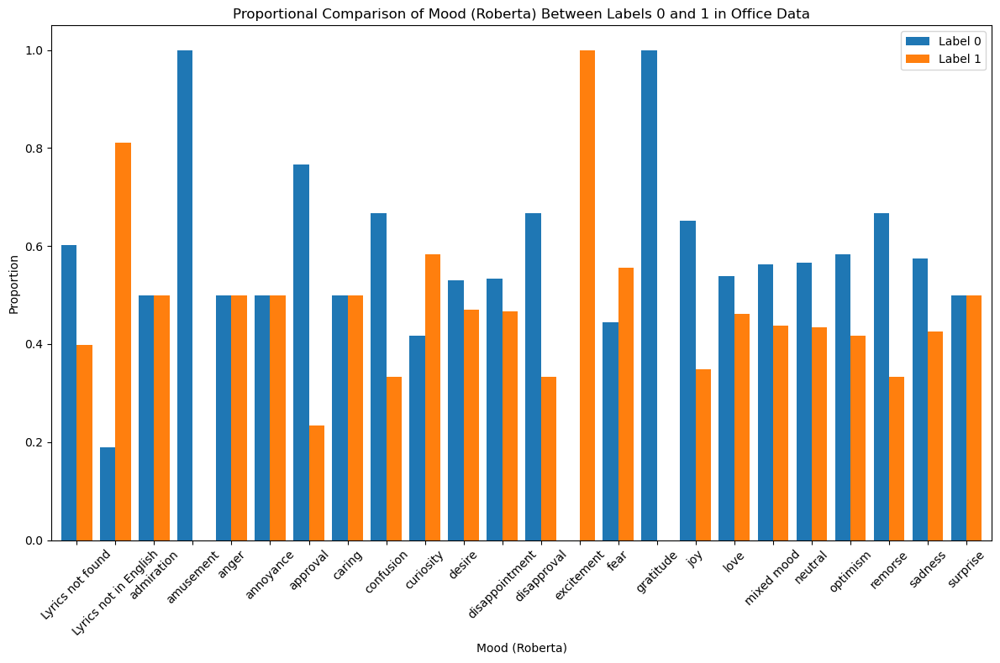

In [119]:

plot_proportional_comparison(
    df=office_df, 
    column_name='final_mood_jhart', 
    title='Proportional Comparison of Mood (Distilroberta) Between Labels 0 and 1 in Office Data', 
    xlabel='Mood (Distilroberta)'
)


plot_proportional_comparison(
    df=office_df, 
    column_name='final_mood_mitch', 
    title='Proportional Comparison of Mood (Distilroberta Mitch) Between Labels 0 and 1 in Office Data', 
    xlabel='Mood (Distilroberta Mitch)'
)


plot_proportional_comparison(
    df=office_df, 
    column_name='target_group', 
    title='Proportional Comparison of Target Group Between Labels 0 and 1 in Office Data', 
    xlabel='Target Group'
)


plot_proportional_comparison(
    df=office_df, 
    column_name='generation', 
    title='Proportional Comparison of Song Release Generation Between Labels 0 and 1 in Office Data', 
    xlabel='Generation'
)


plot_proportional_comparison(
    df=office_df, 
    column_name='final_mood_roberta', 
    title='Proportional Comparison of Mood (Roberta) Between Labels 0 and 1 in Office Data', 
    xlabel='Mood (Roberta)'
)


## Bar

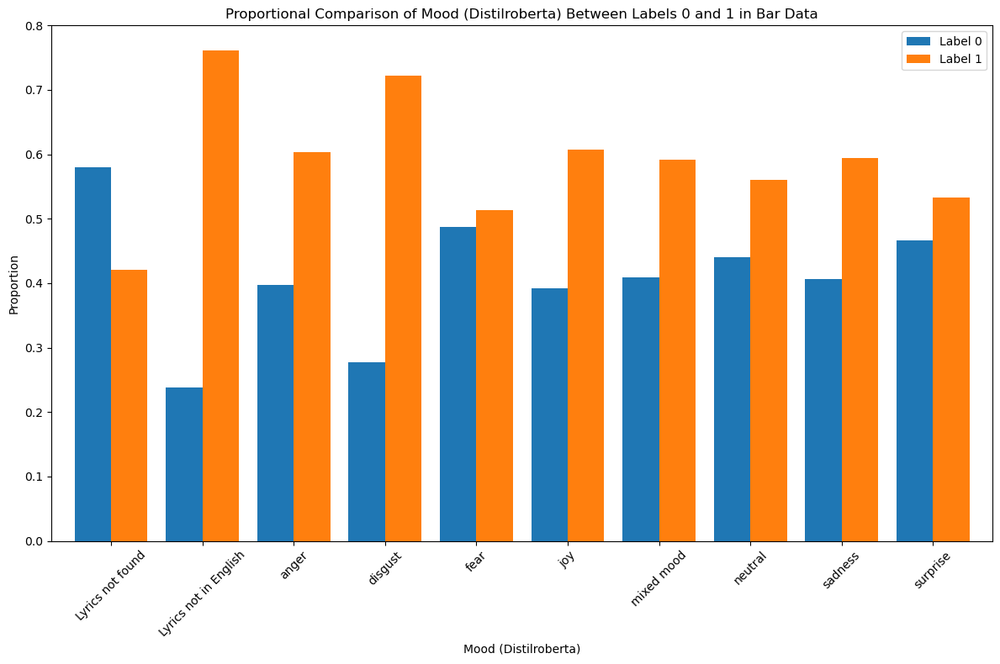

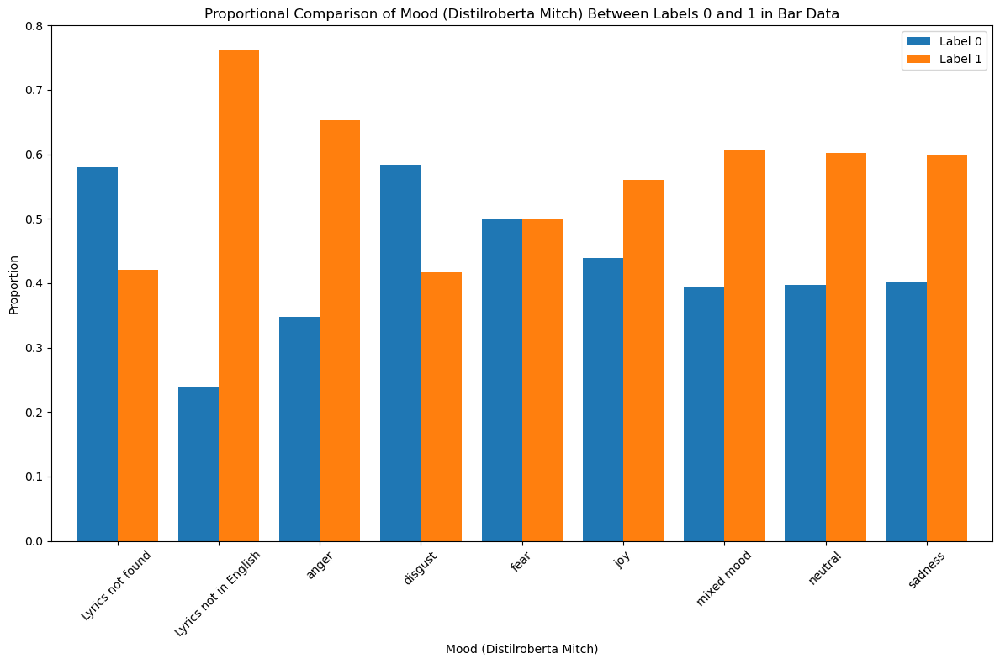

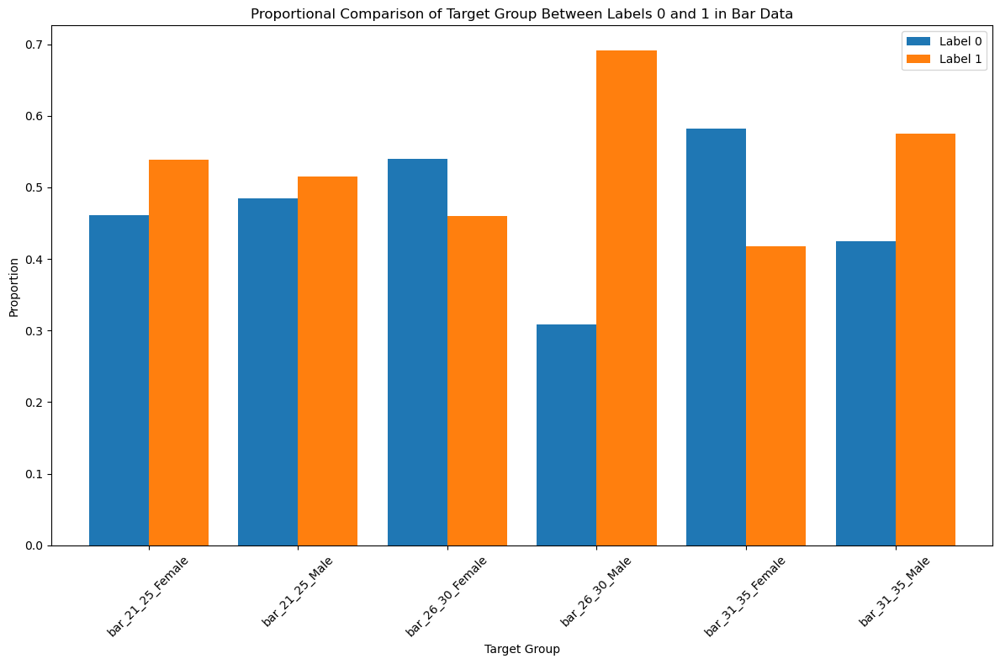

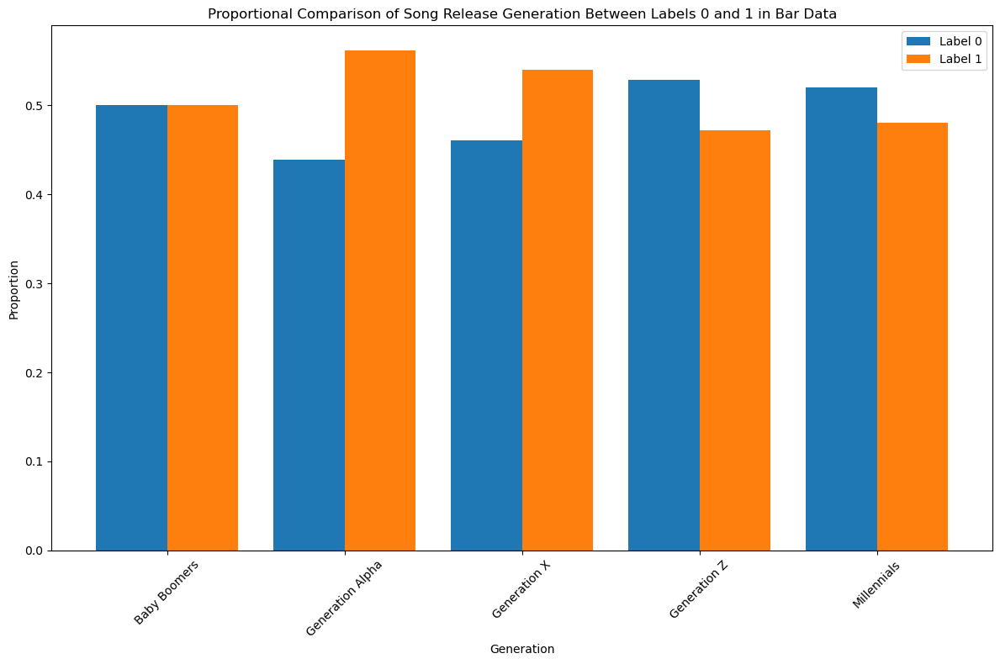

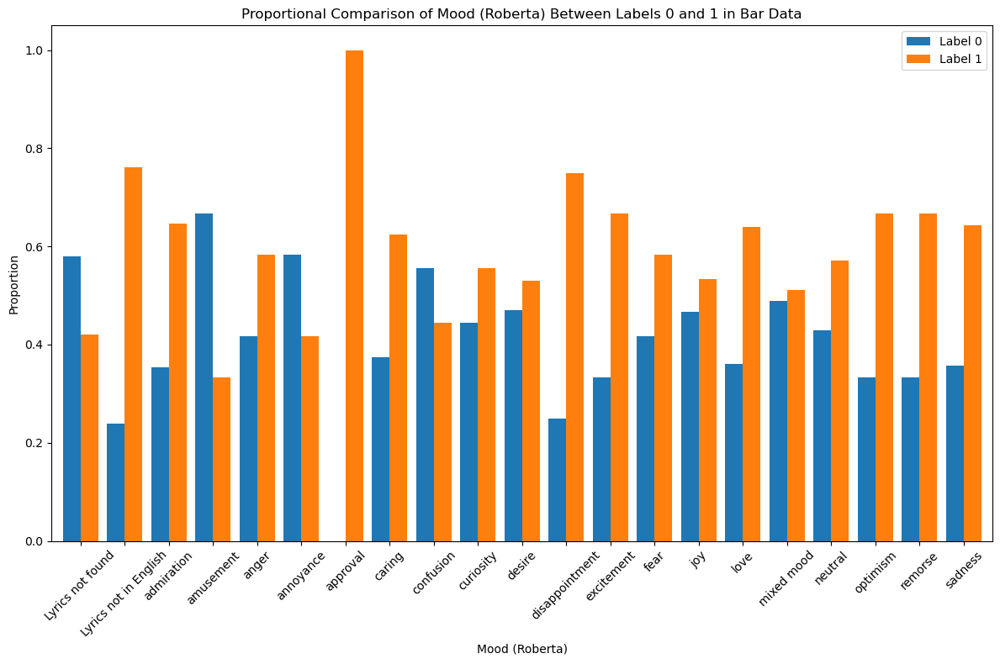

In [120]:

plot_proportional_comparison(
    df=bar_df, 
    column_name='final_mood_jhart', 
    title='Proportional Comparison of Mood (Distilroberta) Between Labels 0 and 1 in Bar Data', 
    xlabel='Mood (Distilroberta)'
)


plot_proportional_comparison(
    df=bar_df, 
    column_name='final_mood_mitch', 
    title='Proportional Comparison of Mood (Distilroberta Mitch) Between Labels 0 and 1 in Bar Data', 
    xlabel='Mood (Distilroberta Mitch)'
)


plot_proportional_comparison(
    df=bar_df, 
    column_name='target_group', 
    title='Proportional Comparison of Target Group Between Labels 0 and 1 in Bar Data', 
    xlabel='Target Group'
)


plot_proportional_comparison(
    df=bar_df, 
    column_name='generation', 
    title='Proportional Comparison of Song Release Generation Between Labels 0 and 1 in Bar Data', 
    xlabel='Generation'
)

plot_proportional_comparison(
    df=bar_df, 
    column_name='final_mood_roberta', 
    title='Proportional Comparison of Mood (Roberta) Between Labels 0 and 1 in Bar Data', 
    xlabel='Mood (Roberta)'
)


## Bedroom

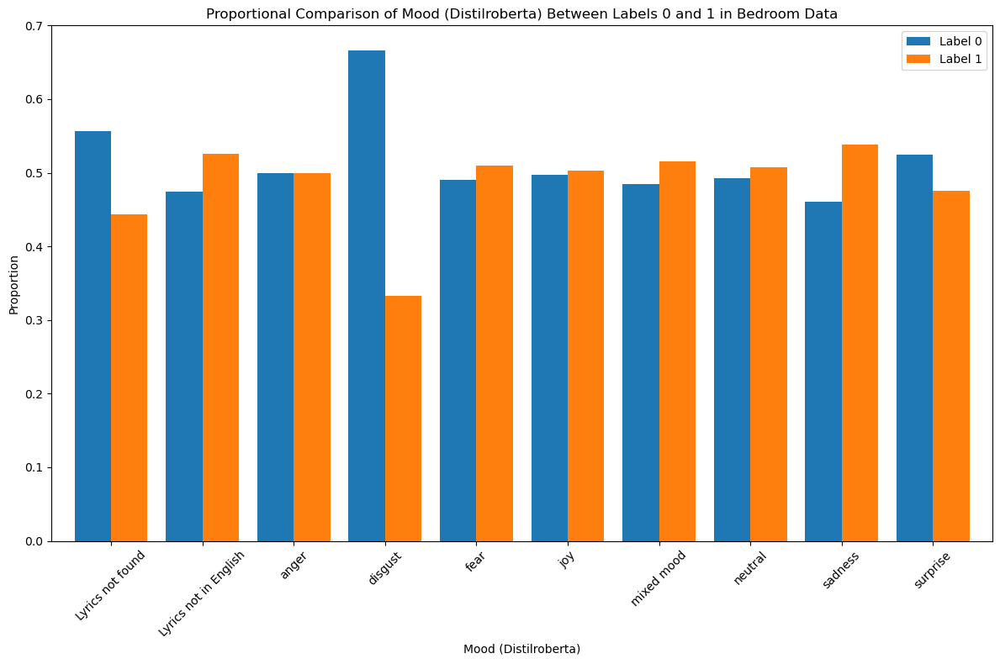

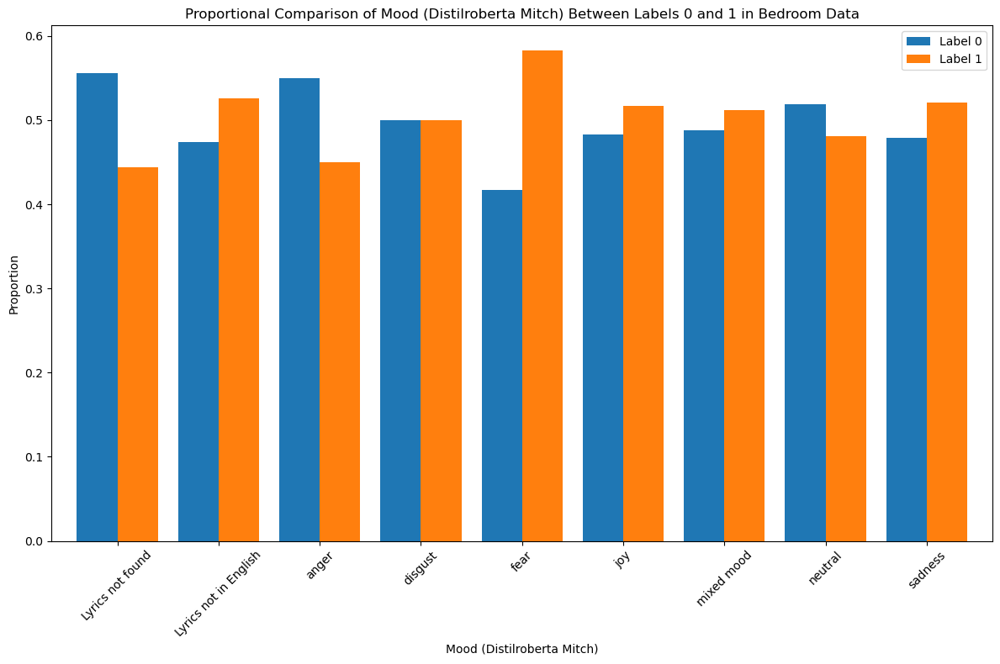

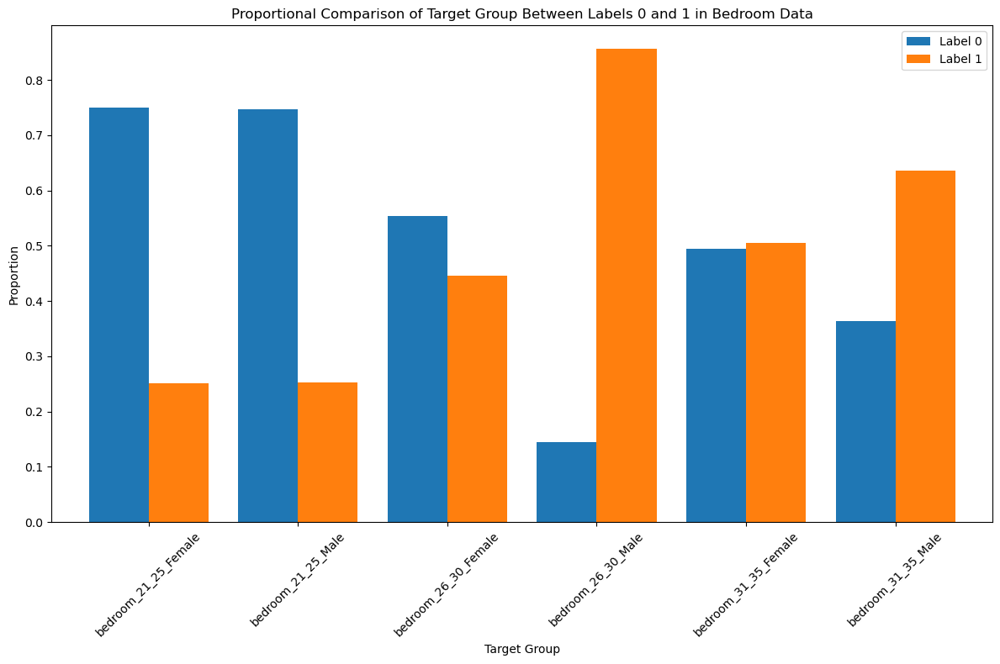

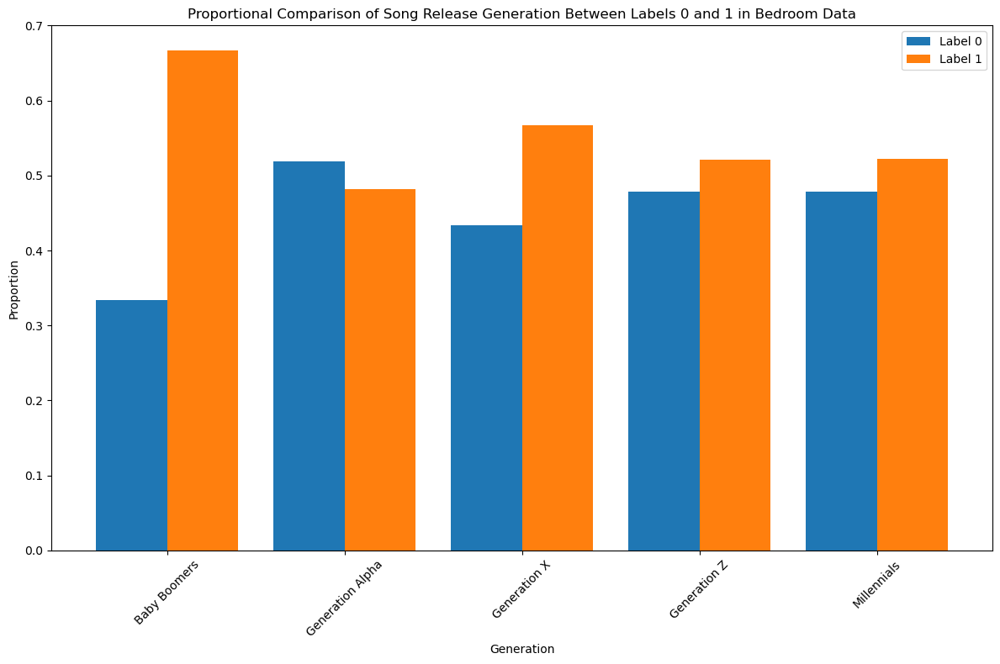

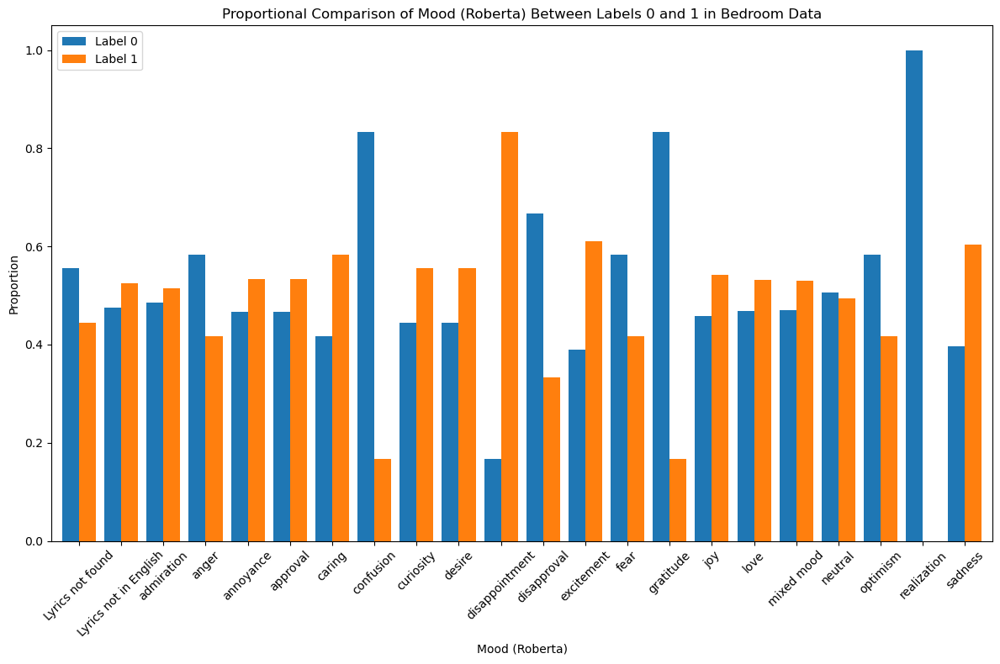

In [121]:

plot_proportional_comparison(
    df=bedroom_df, 
    column_name='final_mood_jhart', 
    title='Proportional Comparison of Mood (Distilroberta) Between Labels 0 and 1 in Bedroom Data', 
    xlabel='Mood (Distilroberta)'
)


plot_proportional_comparison(
    df=bedroom_df, 
    column_name='final_mood_mitch', 
    title='Proportional Comparison of Mood (Distilroberta Mitch) Between Labels 0 and 1 in Bedroom Data', 
    xlabel='Mood (Distilroberta Mitch)'
)


plot_proportional_comparison(
    df=bedroom_df, 
    column_name='target_group', 
    title='Proportional Comparison of Target Group Between Labels 0 and 1 in Bedroom Data', 
    xlabel='Target Group'
)


plot_proportional_comparison(
    df=bedroom_df, 
    column_name='generation', 
    title='Proportional Comparison of Song Release Generation Between Labels 0 and 1 in Bedroom Data', 
    xlabel='Generation'
)


plot_proportional_comparison(
    df=bedroom_df, 
    column_name='final_mood_roberta', 
    title='Proportional Comparison of Mood (Roberta) Between Labels 0 and 1 in Bedroom Data', 
    xlabel='Mood (Roberta)'
)


# Count Plot for Categorical Features

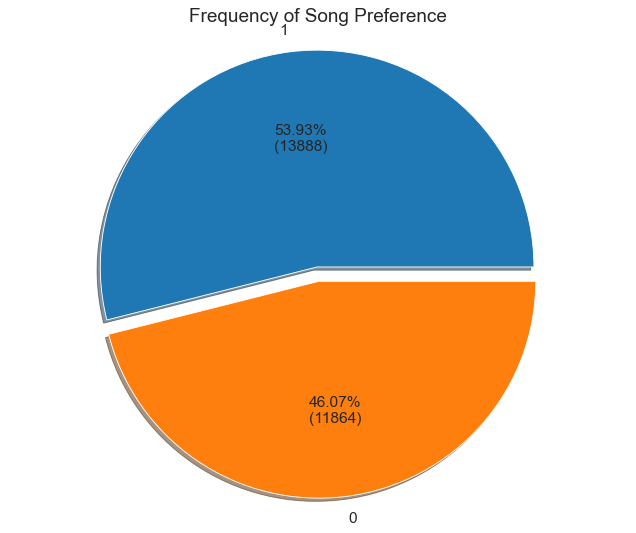

In [138]:
# Set size and outlook
plt.figure(figsize=(10, 8), dpi=80)
sns.set_style('darkgrid',{'axes.facecolour':'.9'})
sns.set_context('paper')

# Find the proportion of churn
total = len(data['label'])
def my_fmt(x):
    return '{:.2f}%\n({:.0f})'.format(x, total*x/100)

# Creat pie chart
plt.pie(data['label'].value_counts().values, labels=data['label'].value_counts().index,
        pctdistance=0.6, shadow=True, labeldistance=1.1, radius=1.5, explode=[0.1,0], 
        textprops={'fontsize': 14},autopct=my_fmt)
plt.title('Frequency of Song Preference', fontsize=17)

# Adjust layout and show plot
plt.axis('equal')
plt.show()

In [145]:
data = data.drop(columns = ['S/N'])

In [146]:
data.columns

Index(['track_id', 'track_name', 'artist_name', 'artist_id', 'release_date',
       'genre', 'key', 'liveness', 'loudness', 'mode', 'popularity',
       'acousticness', 'speechiness', 'tempo', 'valence', 'danceability',
       'energy', 'lyrics', 'cleaned_lyrics', 'Section_1', 'Section_2',
       'Section_3', 'Section_4', 'Section_5', 'Section_6', 'Section_7',
       'Section_8', 'Section_9', 'Section_10', 'section_moods',
       'section_mood_mitch', 'section_mood_jhart', 'final_mood_roberta',
       'final_mood_mitch', 'final_mood_jhart', 'label', 'target_group',
       'first_genre'],
      dtype='object')

In [139]:
def plot_numerical_features(data, bins=20):
    
    # Selecting numerical columns
    NumericalData = data.select_dtypes(include='number')

    # Get the number of columns
    NumCols = NumericalData.shape[1]

    # Create subplots
    fig, axis_rows = plt.subplots(NumCols // 4, 4, figsize=(20, 20))

    # Flatten the array of subplots
    axis_rows = axis_rows.flatten()

    # Loop through numerical columns
    for i in range(NumCols):
        # Check if there are more subplots to use
        if i < len(axis_rows):
            axis_rows[i].hist(x=NumericalData.iloc[:, i], bins=bins)
            axis_rows[i].set_title(f'Histogram: {NumericalData.columns[i]}')

    # Adjust layout
    plt.tight_layout()
    plt.show()

    # Create boxplot
    plt.figure(figsize=(15, 8))
    sns.boxplot(data=NumericalData)
    plt.title('Boxplot of Numerical Features')
    plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
    plt.show()

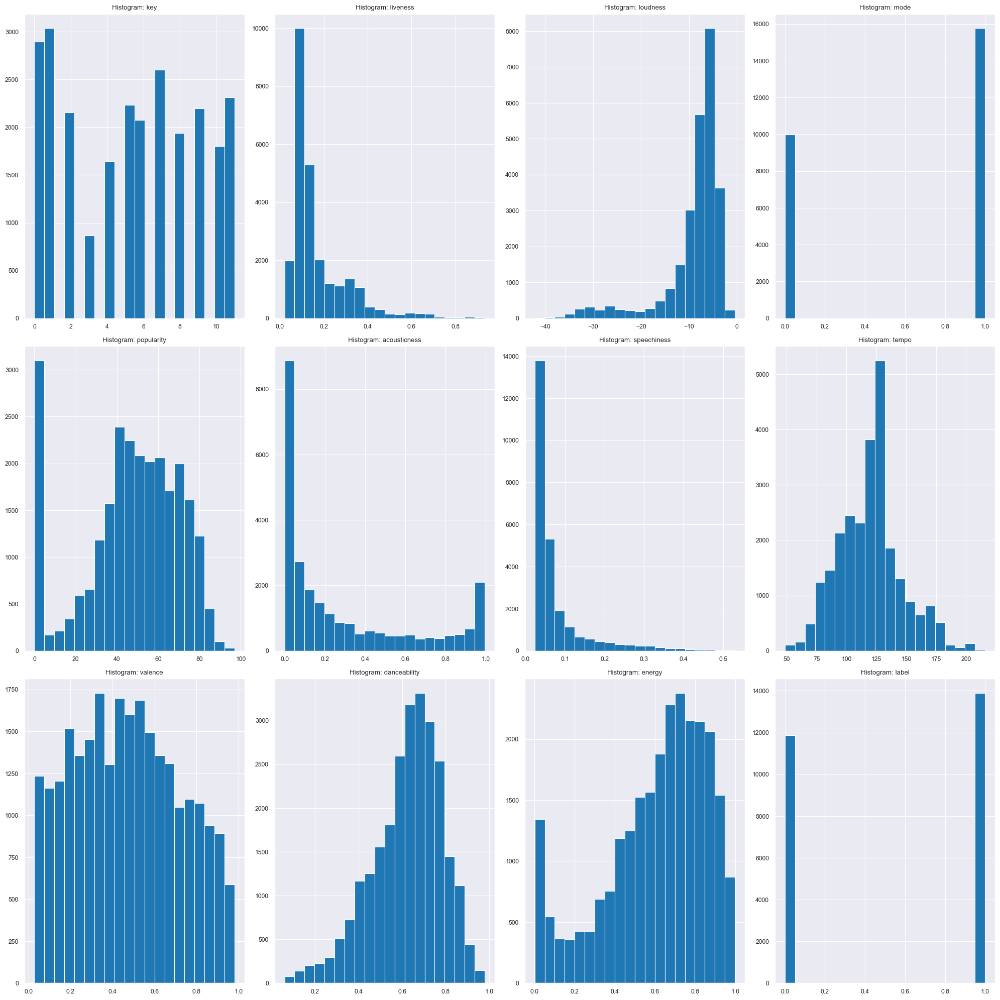

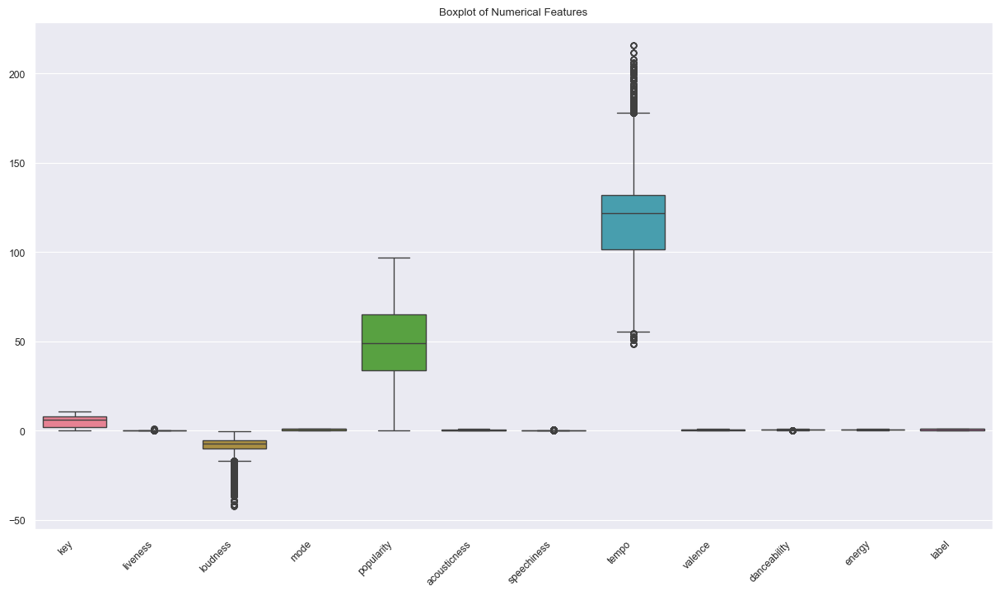

In [147]:
plot_numerical_features(data, bins=20)

In [154]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_single_countplot(data, column_name):
    """
    Plots a count plot for the specified column in the DataFrame.

    Args:
        data (pd.DataFrame): The DataFrame containing the data.
        column_name (str): The name of the column for which the count plot should be created.

    Returns:
        None
    """
    # Set the plot size
    plt.figure(figsize=(10, 6))

    # Create countplot for the specified column
    sns.countplot(x=data[column_name])

    # Set title for the plot
    plt.title(f'Countplot for {column_name}')

    # Rotate x-axis labels for better readability
    plt.xticks(rotation=45)

    # Display the plot
    plt.tight_layout()
    plt.show()


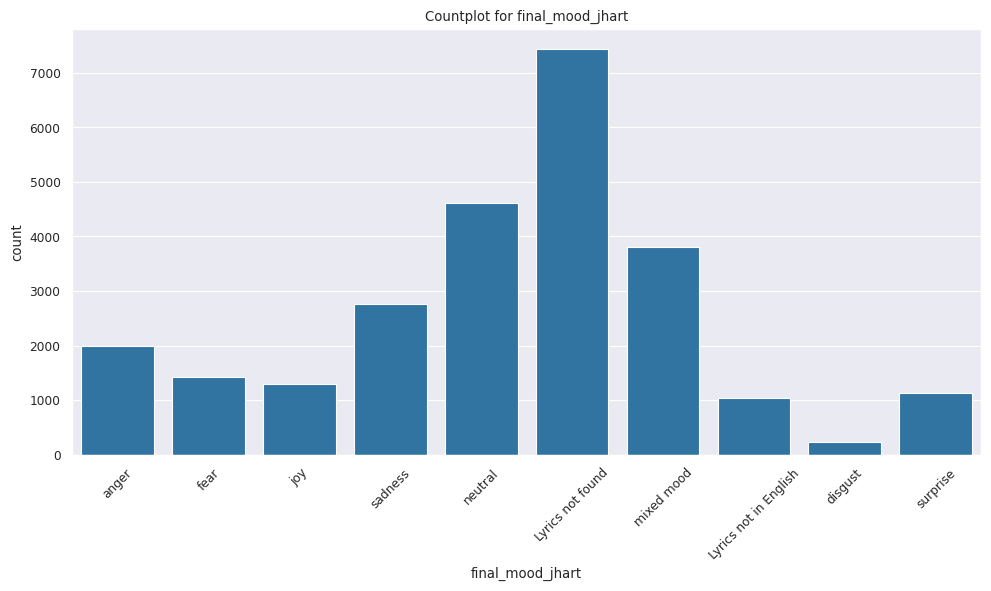

In [156]:
plot_single_countplot(data, "final_mood_jhart")

In [157]:
data.columns

Index(['track_id', 'track_name', 'artist_name', 'artist_id', 'release_date',
       'genre', 'key', 'liveness', 'loudness', 'mode', 'popularity',
       'acousticness', 'speechiness', 'tempo', 'valence', 'danceability',
       'energy', 'lyrics', 'cleaned_lyrics', 'Section_1', 'Section_2',
       'Section_3', 'Section_4', 'Section_5', 'Section_6', 'Section_7',
       'Section_8', 'Section_9', 'Section_10', 'section_moods',
       'section_mood_mitch', 'section_mood_jhart', 'final_mood_roberta',
       'final_mood_mitch', 'final_mood_jhart', 'label', 'target_group',
       'first_genre'],
      dtype='object')

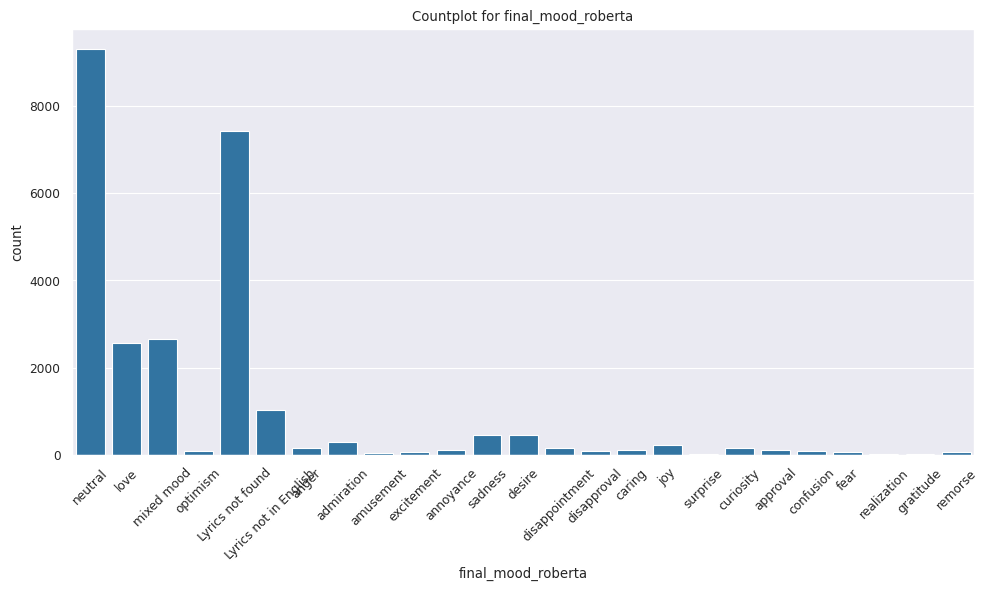

In [158]:
plot_single_countplot(data, "final_mood_roberta")

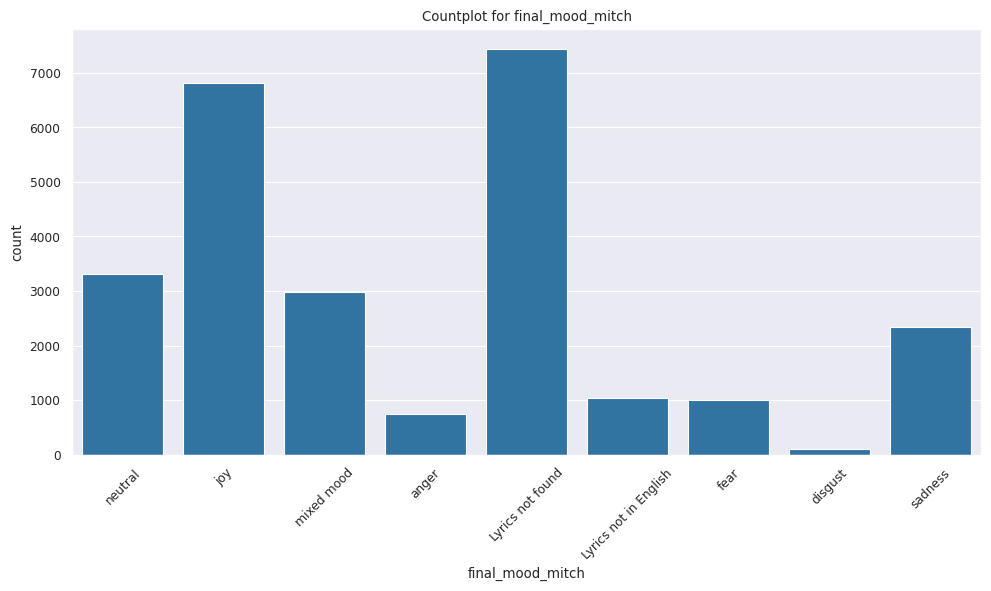

In [159]:
plot_single_countplot(data, "final_mood_mitch")

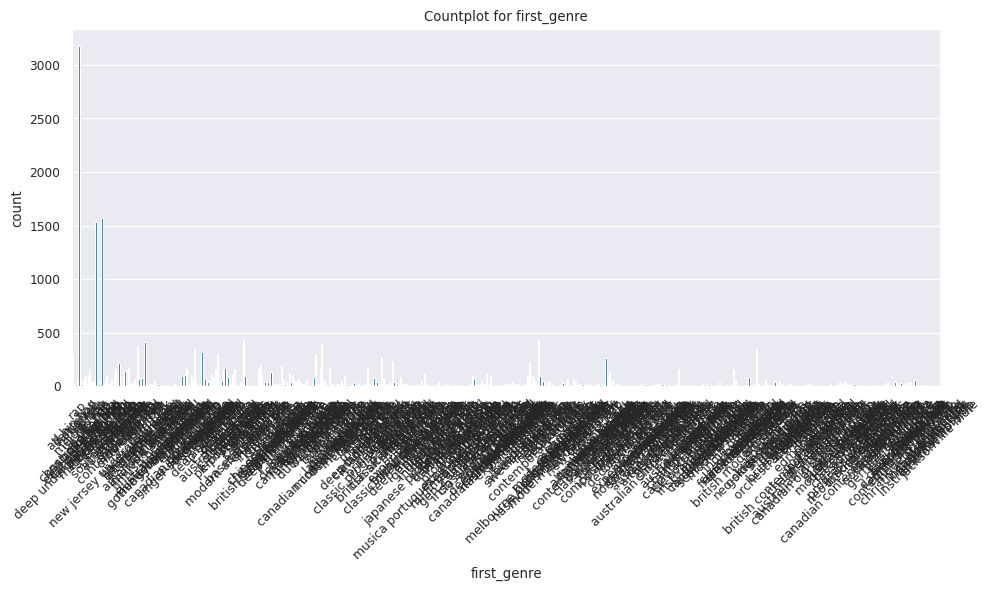

In [160]:
plot_single_countplot(data, "first_genre")

,key,liveness,loudness,mode,popularity,acousticness,speechiness,tempo,valence,danceability,energy,label
count,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000,25752.000000
mean,5.321295,0.172017,-8.977620,0.612069,46.633737,0.288935,0.075993,119.858058,0.470744,0.623096,0.607757,0.539298
std,3.612656,0.132966,6.423934,0.487288,23.711030,0.330881,0.074424,26.215609,0.251484,0.161813,0.253684,0.498463
min,0.000000,0.021000,-42.185000,0.000000,0.000000,0.000002,0.023200,48.515000,0.028300,0.061100,0.002010,0.000000
25%,2.000000,0.094675,-9.864750,0.000000,34.000000,0.026000,0.036200,101.436000,0.265000,0.529750,0.468000,0.000000
50%,6.000000,0.117000,-6.998000,1.000000,49.000000,0.134000,0.046600,121.980000,0.465000,0.646000,0.661000,1.000000
75%,8.000000,0.204000,-5.287750,1.000000,65.000000,0.484250,0.075925,132.031250,0.666000,0.738000,0.802000,1.000000
max,11.000000,0.934000,-0.424000,1.000000,97.000000,0.996000,0.530000,215.861000,0.981000,0.979000,0.998000,1.000000
